# FARSITE Parallelized Full-Fire Simulations (multi-fire, multistep)

Runs FARSITE **from the first to the last observed perimeter** of each fire, in
30-minute steps (`forward_pass_farsite_multistep`), with **hourly weather** fed
to every step. It is a pure forward run: the simulation is never reset to an
observation. It is scored against **every** observed perimeter along the way.

The only fire-specific inputs are in the `FIRES` registry (Section 2):
name, year, ignition lat/lon, start/end datetime and LANDFIRE fuel version.
Everything else (perimeters, landscape, weather, run, evaluation) is generic.

**Pipeline per fire**
1. Get observed perimeters: from a satellite **overlay HTML** if the fire has one (NIROPS + FEDS series), otherwise from `WIFIRE:view_historical_fires`
2. Build a per-fire `landscape.lcp` covering all observed perimeters + buffer (LANDFIRE → `lcpmake`), cached
3. Fetch an hourly weather time series from the nearest station (pylaski), cached
4. Run FARSITE segment-by-segment between consecutive observed perimeters (30-min steps inside each segment)
5. Score IoU / Sørensen / area error at each observed time, against the main observed part (`iou`: the part nearest ignition for ignition starts, otherwise the largest) and all parts (`iou_full`); save GeoPackage, CSV and figures

**Requires the patched `farsite.py`** (time-varying weather, correct humidity units,
final-perimeter extraction, temp-file cleanup).

**Prerequisites:** `TestFARSITE`, `lcpmake`, `NoBarrier/NoBarrier.shp` next to this notebook, and
```bash
chmod +x TestFARSITE lcpmake install_packages.sh
```

In [1]:
# Run once per environment, then switch the kernel to "Python (gdal_env)"
#!chmod +x TestFARSITE lcpmake install_packages.sh && ./install_packages.sh

## 1. Setup

In [2]:
import os, io, json, time, zipfile, warnings, datetime, traceback, logging

# Quiet GDAL/PROJ chatter: "PROJ: proj_create_from_database ... failed" (a missing proj.db in the conda env;
# harmless here) and "EPSG:5070 ... from GeoTIFF keys is not the same" (LANDFIRE rasters). Set False to see
# them again. Takes effect from a fresh kernel, because GDAL reads these settings once at start-up.
QUIET_GDAL = True
if QUIET_GDAL:
    os.environ.setdefault('CPL_LOG', os.devnull)            # GDAL's own message printer → discarded
    os.environ.setdefault('GTIFF_SRS_SOURCE', 'GEOKEYS')    # use the CRS stored in the GeoTIFFs; no registry check
    warnings.filterwarnings('ignore', message=r'.*(PROJ|proj_create|GeoTIFF keys).*')
    for _name in ('fiona', 'pyogrio', 'rasterio'):
        logging.getLogger(_name).setLevel(logging.CRITICAL)
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import requests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from shapely.geometry import Point, Polygon, MultiPolygon, box
from shapely.ops import unary_union
from shapely.validation import make_valid

os.chdir(Path(os.path.abspath('')))

import farsite
from farsite import (forward_pass_farsite_multistep, validate_geom, full_geom, polygonal_parts,
                     DEFAULT_DIST_RES, DEFAULT_PERIM_RES,
                     DEFAULT_TEMPERATURE, DEFAULT_HUMIDITY)

assert 'return_history' in forward_pass_farsite_multistep.__code__.co_varnames, \
    'This notebook needs the patched farsite.py (time-varying weather / history support).'

# Live progress log for headless runs (run_parallel.py sets FARSITE_LOG): everything printed also goes to that file
import sys
if os.environ.get('FARSITE_LOG') and not getattr(sys.stdout, '_farsite_tee', False):
    class _Tee:
        _farsite_tee = True
        def __init__(self, stream, fh): self._s, self._f = stream, fh
        def write(self, txt): self._s.write(txt); self._f.write(txt); return len(txt)
        def flush(self): self._s.flush(); self._f.flush()
        def __getattr__(self, name): return getattr(self._s, name)
    _logfh = open(os.environ['FARSITE_LOG'], 'a', buffering=1)
    sys.stdout, sys.stderr = _Tee(sys.stdout, _logfh), _Tee(sys.stderr, _logfh)

print('Imports OK  |  cwd:', Path.cwd())

Imports OK  |  cwd: /home/jovyan/work/FARSITE_demo


## 2. Settings and fire registry

**Global settings** apply to every fire. **`FIRES`** holds the only per-fire inputs.

Per-fire keys:

| key | required | meaning |
|---|---|---|
| `name` | ✓ | **Exact, case-sensitive** `fire_name` in the layer (e.g. `'GLASS'`). Run `find_fire_names(key)` if unsure |
| `year` | ✓ | Keeps only perimeters from this year (fire names repeat across years) |
| `ignition` | ✓ | `(lat, lon)` WGS84. Weather station lookup, spatial filter, LCP domain, optional ignition-start |
| `start`, `end` | ✓ | Local datetime strings. `start` is the ignition time when `start_from='ignition'`. The run ends at the last observed perimeter before `end` |
| `fuel_version` | | LANDFIRE fuel vintage, e.g. `'LF2016'`, `'LF2023'` (should **pre-date** the fire) |
| `start_from` | | `'ignition'` (circle of `IGNITION_RADIUS_M` at `ignition`, at `start`; used for all five fires because `view_historical_fires` has too few perimeters for them) or `'perimeter'` (first observed perimeter; needs ≥2) |
| `search_radius_km` | | Drop same-name perimeters farther than this from ignition (default 40) |
| `overlay` | | Path to a satellite overlay HTML. Perimeters (and, by default, ignition point/time) come from it instead of Firemap |
| `overlay_ignition` | | Per-fire override of `OVERLAY_IGNITION` |
| `live_fm` | | `(herbaceous, woody)` live fuel moisture % for this fire (default `LIVE_FUEL_MOISTURE`) |
| `score_series` | | Overlay series to score against (default `OVERLAY_SCORE_SERIES` = NIROPS + FEDS) |
| `lcp_buffer_km`, `dist_res`, `perim_res`, `max_sim_days` | | Per-fire overrides of the globals |

Ignition coordinates and start times come from the CAL FIRE / InciWeb incident records. `end` is the reported containment time.
In practice the run stops at the last perimeter the layer has before `end`. **Bobcat and CZU run for weeks**, which means
thousands of FARSITE steps. Use `max_sim_days` or an earlier `end` to cap them.

In [3]:
# ---------------------------------------------------------------- global settings
GEOSERVER_WFS    = 'https://firemap.sdsc.edu/geoserver/wfs'
GEOSERVER_LAYER  = 'WIFIRE:view_historical_fires'
NAME_FIELD       = 'fire_name'            # schema as used in firemap.py
TIME_FIELD       = 'perimeter_timestamp'
YEAR_FIELD       = 'year'                 # used in the CQL filter if the layer accepts it; set None to skip
PERIMETER_TZ     = 'UTC'     # timezone of timed stamps without an offset ('Z' suffixes are always UTC)
DAILY_PERIMETER_HOUR = 0     # local hour assigned to date-only stamps like '2020-09-28Z'
WFS_TIMEOUT      = (15, 180) # (connect, read) seconds

LOCAL_TZ         = 'America/Los_Angeles'   # FARSITE runs on local clock time (diurnal behaviour)

LANDFIRE_EMAIL         = 'h7ahmed@ucsd.edu'   # ← change this
LANDFIRE_PRIORITY_CODE = 'K3LS9F'
LANDFIRE_TOPO_LAYERS   = ['LF2020_Elev', 'LF2020_SlpP', 'LF2020_Asp']
LANDFIRE_RESOLUTION_M  = 90
LCP_BUFFER_KM          = 25      # landscape extends this far beyond all observed perimeters. FARSITE crashes (exit -11)
                                 # if a simulated fire reaches the edge, and free runs overshoot, so be generous.
                                 # A cached landscape built with a smaller buffer is rebuilt automatically.

WX_URL           = 'https://firemap.sdsc.edu/pylaski/stations/data'
WX_NAIVE_TZ      = 'UTC'     # timezone used for pylaski 'from'/'to' and for naive timestamps it returns
WX_CHUNK_DAYS    = 3         # request length per pylaski call
WX_MAX_GAP_HOURS = 3         # if no obs inside a step, use nearest obs within this gap, else defaults
FUEL_MOISTURE_FROM_WEATHER = True   # dead 1/10/100-h fuel moisture from hourly temperature + RH (NFDRS EMC with
                                    # 1/10/100-h time lags). False = fixed farsite.FUEL_MOISTURES_DATA.
LIVE_FUEL_MOISTURE = (30, 60)       # (live herbaceous, live woody) %; per fire: live_fm=(herb, woody)
FM_SPINUP_HOURS    = 72             # weather is fetched this long before ignition so slow fuels start realistic
WX_DEFAULTS      = {'windspeed': 5.0, 'winddirection': 270.0,
                    'temperature': DEFAULT_TEMPERATURE, 'humidity': DEFAULT_HUMIDITY}

DIST_RES         = DEFAULT_DIST_RES    # m
PERIM_RES        = DEFAULT_PERIM_RES   # m
STEP_MINUTES     = 30
MIN_REMAINDER_MIN = 30       # FARSITE rejects very short runs: leftovers are folded into the previous 30-min step,
                             # and a whole segment shorter than this is not simulated (perimeter carried forward)
SPOT_PROBABILITY  = 0.5      # FARSITE_SPOT_PROBABILITY. Heavy spotting can make steps very slow (timeouts);
                             # your farsite_service.py uses 0. Try 0 if steps keep timing out.
MAX_SIM_DAYS     = None      # global cap on simulated duration (None = full window)
FARSITE_TIMEOUT_MIN = 20     # per FARSITE call (30–59 simulated min)
FARSITE_NCORES   = 4
IGNITION_RADIUS_M = 100      # used only when start_from='ignition'
IGNITION_SIMPLIFY_M = 30     # smooth each step's input perimeter by this tolerance (m) before FARSITE;
                             # very jagged perimeters can crash FARSITE. 0 = off.

OUTPUT_ROOT      = Path('fires')
farsite.FARSITE_SPOT_PROBABILITY = SPOT_PROBABILITY   # read by farsite.Config_File for every step
BASEMAP          = 'Esri.WorldTopoMap'  # map tiles for figures, e.g. 'Esri.WorldImagery' (satellite); None = no basemap.
                                        # OpenStreetMap blocks scripted downloads; CARTO now requires an API key.

# satellite overlay perimeters (fires with an 'overlay' entry)
OVERLAY_SCORE_SERIES = ['nirops', 'feds']   # series scored (each at its own timestamps)
OVERLAY_IGNITION     = 'auto'   # ignition point from the overlay: 'auto' (candidate closest to the earliest
                                # perimeter), 'primary', a source label (e.g. 'MTBS event ID'), or None (registry)
OVERLAY_SCAR_LEAD_H  = 12       # perimeters mapped this long before ignition are treated as older burn scars
OVERLAY_SCAR_IOU     = 0.8      # later parts overlapping such a scar this much (IoU) are dropped
FEDS_RETIME_TO_VIIRS = True     # FEDS labels are 12-h bin STARTS; re-time each to its latest VIIRS detection
FEDS_BIN_HOURS       = 12

In [4]:
# ---------------------------------------------------------------- fire registry
FIRES = {
    # With an overlay, ignition point/time and perimeters come from the overlay (Section 3b);
    # name/year/ignition/start below are only used as a fallback if the overlay file is missing.
    'Airport_2024': dict(
        name='AIRPORT', year=2024,
        ignition=(33.6677, -117.5662),          # Trabuco Canyon (CAL FIRE)
        overlay='overlays/CA2024_AIRPORT_overlay.html',
        score_series=['nirops'],                # this overlay has no FEDS series
        start='2024-09-09 13:21', end='2024-10-05 22:00',
        start_from='ignition',
        fuel_version='LF2023',
    ),
    'Zogg_2020': dict(
        name='ZOGG', year=2020,
        ignition=(40.5392, -122.5660),          # Zogg Mine Rd & Jenny Bird Ln, N of Igo (approx.)
        overlay='overlays/CA2020_ZOGG_overlay.html',
        start='2020-09-27 15:00', end='2020-10-13 17:00',
        start_from='ignition',
        fuel_version='LF2016',
    ),
    'Bobcat_2020': dict(
        name='BOBCAT', year=2020,
        ignition=(34.2480, -117.9590),          # Cogswell Dam (MTBS; matches the earliest perimeters)
        overlay='overlays/CA2020_BOBCAT_overlay.html',
        start='2020-09-06 12:21', end='2020-12-18 00:00',
        start_from='ignition',
        fuel_version='LF2016',
        max_sim_days=21,                        # ← long fire: cap (remove to run everything)
    ),
    'CZU_2020': dict(
        name='CZU LIGHTNING COMPLEX', year=2020,
        ignition=(37.2581, -122.2176),          # IRWIN origin (complex: several lightning ignitions)
        overlay='overlays/CA2020_CZU_LIGHTNING_COMPLEX_overlay.html',
        start='2020-08-16 06:41', end='2020-09-22 20:00',
        start_from='ignition',
        fuel_version='LF2016',
        max_sim_days=21,                        # ← long fire: cap (remove to run everything)
    ),
    'Glass_2020': dict(
        name='GLASS', year=2020,
        ignition=(38.5630, -122.4975),          # GOFER first-detection point (inside the early perimeters)
        overlay='overlays/CA2020_GLASS_overlay.html',
        start='2020-09-27 03:48', end='2020-10-20 11:00',
        start_from='ignition',
        fuel_version='LF2016',
    ),
}

# Which fires to run in Section 9
FIRES_TO_RUN = list(FIRES)          # e.g. ['Glass_2020']
DRY_RUN      = True                 # True: fetch perimeters + plan only (no LANDFIRE / FARSITE). Flip to False to simulate.

# Overrides for headless / parallel runs (set by run_parallel.py; ignored when the variables aren't set)
if os.environ.get('FARSITE_FIRES'):
    FIRES_TO_RUN = [k.strip() for k in os.environ['FARSITE_FIRES'].split(',') if k.strip()]
    _unknown = [k for k in FIRES_TO_RUN if k not in FIRES]
    assert not _unknown, f'FARSITE_FIRES has unknown fires {_unknown}; known: {list(FIRES)}'
if os.environ.get('FARSITE_DRY_RUN'):
    DRY_RUN = os.environ['FARSITE_DRY_RUN'] == '1'
if os.environ.get('FARSITE_NCORES'):
    FARSITE_NCORES = int(os.environ['FARSITE_NCORES'])
if os.environ.get('FARSITE_MAX_SIM_DAYS'):          # quick end-to-end checks: cap every fire
    _cap = float(os.environ['FARSITE_MAX_SIM_DAYS'])
    for _f in FIRES.values():
        _f['max_sim_days'] = min(_f.get('max_sim_days') or _cap, _cap)
if os.environ.get('FARSITE_SPOT_PROBABILITY'):
    SPOT_PROBABILITY = float(os.environ['FARSITE_SPOT_PROBABILITY'])
    farsite.FARSITE_SPOT_PROBABILITY = SPOT_PROBABILITY
if os.environ.get('FARSITE_SUMMARY_ONLY') == '1':   # just rebuild the combined summaries from disk
    FIRES_TO_RUN = []
print(f'Fires: {FIRES_TO_RUN} | DRY_RUN={DRY_RUN} | FARSITE_NCORES={FARSITE_NCORES} | SPOT_PROBABILITY={SPOT_PROBABILITY}')

Fires: ['Airport_2024', 'Zogg_2020', 'Bobcat_2020', 'CZU_2020', 'Glass_2020'] | DRY_RUN=True | FARSITE_NCORES=4 | SPOT_PROBABILITY=0.5


## 2b. Housekeeping (optional)

Clears old leftovers. With `CLEANUP_DELETE = False` (default) it only **lists** what it would delete.
- `CLEAN_TMP`: leftover FARSITE step files and logs in `tmp/` (failed steps keep theirs for inspection)
- `CLEAN_RUN_LOGS`: `runs/*.log` from `run_parallel.py`. The executed `runs/*.ipynb` are kept.
- `CLEAN_OLD_RESULTS`: per-fire outputs in `fires/<fire>/` and the combined summaries. Cached `landscape.lcp`
  and `weather.csv` are always kept, so nothing has to be downloaded again.

The cell does nothing inside `run_parallel.py` copies, and won't delete while FARSITE processes are running.

In [5]:
CLEAN_TMP         = True
CLEAN_RUN_LOGS    = True
CLEAN_OLD_RESULTS = True
CLEANUP_DELETE    = True     # False: list only. True: delete.

import subprocess
from collections import Counter

def _farsite_running():
    try:
        return subprocess.run(['pgrep', '-f', 'TestFARSITE'], capture_output=True, text=True).stdout.split()
    except FileNotFoundError:
        return []

if os.environ.get('FARSITE_LOG') or os.environ.get('FARSITE_FIRES'):
    print('Headless run (run_parallel.py): housekeeping skipped.')
else:
    tmp = Path(farsite.FARSITE_TMP_DIR)
    targets = []
    if CLEAN_TMP and tmp.exists():
        targets += [p for p in tmp.iterdir() if p.is_file()]
        targets += [p for p in (tmp / 'farsite_logs').glob('*') if p.is_file()]
    if CLEAN_RUN_LOGS:
        targets += sorted(Path('runs').glob('*.log'))
    if CLEAN_OLD_RESULTS and OUTPUT_ROOT.exists():
        keep = {'landscape.lcp', 'weather.csv'}
        for d in OUTPUT_ROOT.iterdir():
            if d.is_dir():
                targets += [p for p in d.iterdir() if p.is_file() and p.name not in keep]
        targets += [p for p in OUTPUT_ROOT.iterdir() if p.is_file()]          # combined summaries/figure

    size_mb = sum(p.stat().st_size for p in targets) / 1e6
    print(f'{len(targets)} file(s), {size_mb:.1f} MB:')
    for folder, n in sorted(Counter(str(p.parent) for p in targets).items()):
        print(f'  {folder}/  {n} file(s)')
    if not CLEANUP_DELETE:
        print('\nNothing deleted (CLEANUP_DELETE = False). Set it to True and re-run this cell to delete.')
    elif (pids := _farsite_running()):
        print(f'\nFARSITE is running (pids {pids}), probably a run_parallel.py job. Not deleting.')
    else:
        for p in targets:
            p.unlink(missing_ok=True)
        print(f'\nDeleted {len(targets)} file(s).')

238 file(s), 9.4 MB:
  /home/jovyan/work/FARSITE_demo/tmp/  173 file(s)
  /home/jovyan/work/FARSITE_demo/tmp/farsite_logs/  36 file(s)
  fires/  3 file(s)
  fires/Airport_2024/  3 file(s)
  fires/Bobcat_2020/  3 file(s)
  fires/CZU_2020/  3 file(s)
  fires/Glass_2020/  5 file(s)
  fires/Zogg_2020/  12 file(s)

FARSITE is running (pids ['2865', '3706', '4948']), probably a run_parallel.py job. Not deleting.


## 3. Perimeters from WIFIRE

Same query pattern as `firemap.py`: an **exact** match on `fire_name` (indexed, so it's fast), plus `year = <year>` when the
layer supports it. If it doesn't, the year filter is applied locally. A substring `LIKE` filter makes GeoServer scan the whole
historical view, which can hang for minutes.

If a name isn't found, the error lists the `fire_name` values near the ignition point. You can also call
`find_fire_names('CZU_2020')` directly.

In [6]:
def _wfs_get(params, timeout=None):
    base = {'SERVICE': 'WFS', 'VERSION': '2.0.0', 'REQUEST': 'GetFeature',
            'TYPENAMES': GEOSERVER_LAYER, 'OUTPUTFORMAT': 'application/json', 'SRSNAME': 'EPSG:4326'}
    timeout = timeout or WFS_TIMEOUT
    try:
        r = requests.get(GEOSERVER_WFS, params={**base, **params}, timeout=timeout)
    except requests.Timeout:
        raise TimeoutError(f'WFS request timed out after {timeout} s: {params}')
    r.raise_for_status()
    try:
        return r.json().get('features', [])
    except ValueError:                       # GeoServer sends XML ExceptionReports for bad filters
        raise ValueError(f'WFS returned a non-JSON response: {r.text[:300]}')

def inspect_layer(n=3):
    '''Print a few raw records so you can check field names and timestamp format.'''
    for f in _wfs_get({'COUNT': n}):
        print(f['properties'])

def _bbox_around(lat, lon, radius_km):
    dlat = radius_km / 111.0
    dlon = radius_km / (111.0 * np.cos(np.deg2rad(lat)))
    return lon - dlon, lat - dlat, lon + dlon, lat + dlat

def find_fire_names(fire_key_or_cfg, radius_km=None):
    '''List fire_name values (with years and perimeter counts) near a fire's ignition point.
    Uses a spatial BBOX query, which is fast and needs no name filter.'''
    fire = FIRES[fire_key_or_cfg] if isinstance(fire_key_or_cfg, str) else fire_key_or_cfg
    lat, lon = fire['ignition']
    minx, miny, maxx, maxy = _bbox_around(lat, lon, radius_km or fire.get('search_radius_km', 40))
    props = f'{NAME_FIELD},{TIME_FIELD}'
    feats = _wfs_get({'BBOX': f'{minx},{miny},{maxx},{maxy},EPSG:4326', 'PROPERTYNAME': props, 'COUNT': 20000})
    if not feats:   # some GeoServer setups use lat/lon axis order for the URN form
        feats = _wfs_get({'BBOX': f'{miny},{minx},{maxy},{maxx},urn:ogc:def:crs:EPSG::4326',
                          'PROPERTYNAME': props, 'COUNT': 20000})
    if not feats:
        return pd.DataFrame(columns=['fire_name', 'year', 'n_perimeters'])
    df = pd.DataFrame([f['properties'] for f in feats])
    df['year'] = df[TIME_FIELD].astype(str).str[:4]
    return (df.groupby([NAME_FIELD, 'year']).size().rename('n_perimeters').reset_index()
              .rename(columns={NAME_FIELD: 'fire_name'})
              .sort_values(['year', 'n_perimeters'], ascending=[False, False]).reset_index(drop=True))

def _to_local_naive(series, naive_tz):
    '''Parse timestamps (strings or epoch-ms) → naive datetimes in LOCAL_TZ.'''
    s = pd.Series(series)
    if pd.api.types.is_numeric_dtype(s):
        ts = pd.to_datetime(s, unit='ms', utc=True)
    else:
        s = s.astype(str)
        has_tz = s.str.contains(r'(?:Z|[+-]\d\d:?\d\d)$', regex=True)
        ts = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns, UTC]')
        if has_tz.any():
            ts[has_tz] = pd.to_datetime(s[has_tz], utc=True, format='mixed')
        if (~has_tz).any():
            ts[~has_tz] = (pd.to_datetime(s[~has_tz], format='mixed')
                             .dt.tz_localize(naive_tz).dt.tz_convert('UTC'))
    return ts.dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)

def parse_perimeter_times(values):
    '''perimeter_timestamp → naive local datetime.
    Date-only stamps ("2020-09-28Z", the daily format firemap.py mentions) carry no time of day, so they are
    taken as that LOCAL date at DAILY_PERIMETER_HOUR rather than shifted from UTC midnight to the previous evening.
    Full timestamps are converted from PERIMETER_TZ (or their own offset) to LOCAL_TZ.'''
    s = pd.Series(values).astype(str).str.strip()
    date_only = s.str.fullmatch(r'\d{4}-\d{2}-\d{2}(?:T00:00(?::00)?)?Z?')
    out = pd.Series(pd.NaT, index=s.index, dtype='datetime64[ns]')
    if date_only.any():
        out[date_only] = (pd.to_datetime(s[date_only].str[:10])
                          + pd.Timedelta(hours=DAILY_PERIMETER_HOUR))
    if (~date_only).any():
        out[~date_only] = _to_local_naive(s[~date_only].values, PERIMETER_TZ).values
    return out, bool(date_only.all())

def _query_fire(name, year):
    esc = name.replace("'", "''")
    if YEAR_FIELD:
        try:
            feats = _wfs_get({'CQL_FILTER': f"{NAME_FIELD} = '{esc}' AND {YEAR_FIELD} = {int(year)}"})
            if feats:
                return feats
        except (requests.HTTPError, ValueError) as e:
            print(f'  (year filter not accepted by the layer, filtering by year locally: {str(e)[:120]})')
    return _wfs_get({'CQL_FILTER': f"{NAME_FIELD} = '{esc}'"})

def _largest_poly(geom):
    return validate_geom(make_valid(geom))      # geometry.py convention: largest part

def fetch_fire_perimeters(fire, verbose=True):
    '''All perimeters for one fire (EPSG:5070), filtered by exact name, year and distance; sorted by time.'''
    feats = _query_fire(fire['name'], fire['year'])
    if not feats:
        near = find_fire_names(fire)
        raise ValueError(f"No perimeters with {NAME_FIELD} = '{fire['name']}' in {GEOSERVER_LAYER}. "
                         f"Names are exact and case-sensitive. fire_name values near the ignition point:\n"
                         f"{near.head(25).to_string() if len(near) else '(none found)'}")

    gdf = gpd.GeoDataFrame.from_features(feats, crs='EPSG:4326')
    gdf['datetime'], daily = parse_perimeter_times(gdf[TIME_FIELD].values)
    gdf = gdf[gdf['datetime'].dt.year == fire['year']]

    # spatial filter around ignition (guards against same-name fires elsewhere)
    lat, lon = fire['ignition']
    ign = gpd.GeoSeries([Point(lon, lat)], crs='EPSG:4326').to_crs('EPSG:5070').iloc[0]
    gdf = gdf.to_crs('EPSG:5070')
    radius = fire.get('search_radius_km', 40) * 1000
    gdf = gdf[gdf.geometry.distance(ign) <= radius]

    # 'geometry' = largest part (what FARSITE is started from / scored on, as in geometry.py);
    # 'geometry_full' = all parts merged (multi-part perimeters, e.g. separate spot/merged fires)
    gdf['geometry_full'] = gdf.geometry.apply(full_geom)
    gdf['geometry'] = gdf.geometry.apply(_largest_poly)
    gdf = gdf[gdf.geometry.notna() & (gdf.geometry.area > 0)]
    if gdf.empty:
        raise ValueError(f"No perimeters left for {fire['name']} {fire['year']} after year/distance filters")

    # one perimeter per timestamp (largest), sorted
    gdf['area_km2'] = gdf.geometry.area / 1e6
    gdf['area_full_km2'] = gpd.GeoSeries(gdf['geometry_full'], crs='EPSG:5070').area / 1e6
    gdf['n_parts'] = gdf['geometry_full'].apply(lambda g: len(getattr(g, 'geoms', [g])))
    gdf['series'] = 'firemap'
    gdf = (gdf.sort_values(['datetime', 'area_full_km2'])
              .drop_duplicates('datetime', keep='last')
              .reset_index(drop=True))
    gdf = gdf[['series', 'datetime', 'area_km2', 'area_full_km2', 'n_parts', 'geometry', 'geometry_full']]

    gdf.attrs['daily'] = daily
    if verbose:
        print(f"  {len(gdf)} perimeters ({gdf.datetime.min()} → {gdf.datetime.max()})")
        multi = gdf[gdf.n_parts > 1]
        if len(multi):
            print(f"  {len(multi)} multi-part perimeter(s): largest part is "
                  f"{(multi.area_km2 / multi.area_full_km2).min()*100:.0f}–"
                  f"{(multi.area_km2 / multi.area_full_km2).max()*100:.0f}% of the mapped area "
                  f"(scored both ways: iou = main part, iou_full = all parts)")
        if daily:
            print(f'  note: timestamps are date-only (daily perimeters), placed at {DAILY_PERIMETER_HOUR:02d}:00 local; '
                  f'segments are ~24 h and the true mapping time within each day is unknown')
    return gdf

## 3b. Satellite-derived perimeters from overlay HTML files

For fires with an `overlay` entry in `FIRES`, perimeters come from the overlay HTML instead of Firemap. That's the Leaflet
viewer built from FIRMS/GOES detections, with an embedded `D` object holding the perimeter series. Available series:
`gofer_combined`, `gofer_east`, `gofer_west` (hourly, GOES), `feds` (12-hourly, VIIRS), `nirops` (nightly airborne IR) and
`final` (FRAP final perimeter, untimed). Times are exact (minutes after the overlay's `t0`, in UTC).

**Ignition.** Each overlay lists several ignition candidates (IRWIN origin, GOFER metadata, MTBS, CAL FIRE). They don't
always agree. For Bobcat, the IRWIN point is ~14 km from the earliest perimeters and the MTBS point (Cogswell Dam) is inside
them. With `OVERLAY_IGNITION = 'auto'`, the candidate closest to the earliest post-ignition perimeter is used; the primary
wins near-ties. The time always comes from the primary candidate. Override per fire with `overlay_ignition=...`.

**FEDS timing.** FEDS perimeters are labelled with the **start** of a 12-hour bin (05:00/17:00 PT) but include the VIIRS
detections from the whole bin. Glass's "05:00 27 Sep" perimeter already contains the 13:20–15:00 overpasses. With
`FEDS_RETIME_TO_VIIRS = True`, each is re-timed to its latest VIIRS detection (typically ~10 h after the label). The
original label is kept in `label_time`.

**Cleaning.** Same-time perimeters within a series (separate tracks, e.g. fires of a complex) are merged into one
multi-part perimeter. Parts matching a perimeter mapped more than `OVERLAY_SCAR_LEAD_H` before ignition are dropped:
they are an older burn scar, e.g. the 2020 Ranch 2 fire in Bobcat's FEDS series.

In [7]:
import re

_OVERLAY_CACHE = {}
def load_overlay(path):
    # Return the embedded data object `D` from an overlay HTML file.
    path = Path(path)
    if path not in _OVERLAY_CACHE:
        html = path.read_text(encoding='utf-8')
        m = re.search(r'\bD\s*=\s*\{', html)
        if m is None:
            raise ValueError(f'{path}: no embedded `D = {{...}}` data object found')
        D, _ = json.JSONDecoder().raw_decode(html[m.end() - 1:])
        _OVERLAY_CACHE[path] = D
    return _OVERLAY_CACHE[path]

def _overlay_geom(g):
    # Overlay geometry (list of polygons → list of rings → [lat, lon]) → shapely (lon/lat).
    polys = []
    for poly in g or []:
        rings = [[(lon, lat) for lat, lon in ring] for ring in poly if len(ring) >= 3]
        if rings:
            polys.append(Polygon(rings[0], rings[1:]))
    if not polys:
        return None
    return polys[0] if len(polys) == 1 else MultiPolygon(polys)

def _overlay_time(D, minutes):
    t = pd.Timestamp(D['t0']) + pd.Timedelta(minutes=float(minutes))
    return t.tz_convert(LOCAL_TZ).tz_localize(None).round('min')

def overlay_ignition(D):
    # Primary ignition: ((lat, lon), local naive time, source label).
    ign = next((g for g in D.get('ign', []) if g.get('primary')), (D.get('ign') or [None])[0])
    if ign is None:
        return None
    return (ign['lat'], ign['lon']), _overlay_time(D, ign.get('t') or 0), ign.get('source', '?')

def _ign_point(lat, lon):
    return gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(5070).iloc[0]

def _earliest_overlay_perimeter(D):
    # Earliest perimeter at/after t0 across all overlay series (EPSG:5070), used to check ignition candidates.
    best = None
    for key, p in D.get('perims', {}).items():
        for t, g in zip(p['t'], p['g']):
            if t >= 0:
                geom = _overlay_geom(g)
                if geom is not None and (best is None or t < best[0]):
                    best = (t, key, gpd.GeoSeries([geom], crs=4326).to_crs(5070).iloc[0])
                break
    return best

def choose_overlay_ignition(D, mode='auto'):
    # Pick the ignition point from the overlay's candidates (IRWIN, GOFER metadata, MTBS, CAL FIRE, ...).
    #   'auto'    : candidate closest to the earliest post-ignition perimeter; the primary wins near-ties (≤0.5 km)
    #   'primary' : the overlay's primary candidate
    #   '<source>': the candidate whose source label matches, e.g. 'GOFER metadata'
    # The ignition TIME is always the primary's (other candidates carry first-detection or date-only times).
    cands = D.get('ign') or []
    if not cands:
        return None
    primary = next((g for g in cands if g.get('primary')), cands[0])
    t_ign = _overlay_time(D, primary.get('t') or 0)
    if mode == 'primary':
        pick, note = primary, 'primary'
    elif mode != 'auto':
        pick = next((g for g in cands if g['source'].lower() == str(mode).lower()), None)
        if pick is None:
            raise ValueError(f"overlay_ignition={mode!r} not among {[g['source'] for g in cands]}")
        note = 'requested'
    else:
        first = _earliest_overlay_perimeter(D)
        if first is None:
            pick, note = primary, 'primary (no perimeters to check against)'
        else:
            t_first, key, geom = first
            dist = {g['source']: geom.distance(_ign_point(g['lat'], g['lon'])) / 1000 for g in cands}
            best = min(cands, key=lambda g: dist[g['source']])
            pick = primary if dist[primary['source']] - dist[best['source']] <= 0.5 else best
            note = (f"closest to first perimeter ({key} @ +{t_first/60:.1f} h): " +
                    ', '.join(f"{s} {d:.1f} km" for s, d in dist.items()))
    return (pick['lat'], pick['lon']), t_ign, pick['source'], note

def resolve_fire(key):
    # Registry entry, with ignition point/time taken from the overlay when configured.
    fire = dict(FIRES[key])
    ov = fire.get('overlay')
    if ov and not Path(ov).exists():
        print(f'  ⚠ overlay {ov} not found, falling back to Firemap perimeters')
        fire.pop('overlay')
        return fire
    mode = fire.get('overlay_ignition', OVERLAY_IGNITION)
    if ov and mode:
        ig = choose_overlay_ignition(load_overlay(ov), mode)
        if ig is not None:
            (lat, lon), t, src, note = ig
            d_km = (_ign_point(*fire['ignition']).distance(_ign_point(lat, lon)) / 1000
                    if fire.get('ignition') else float('nan'))
            print(f'  ignition from overlay: {src} ({lat:.5f}, {lon:.5f}) at {t}')
            print(f'    {note}')
            print(f'    [registry: {fire.get("ignition")} at {fire.get("start")}, {d_km:.2f} km apart]')
            fire['ignition'], fire['start'] = (lat, lon), str(t)
    return fire

def viirs_acquisition_times(D, label_minutes, bin_h=None):
    # FEDS perimeters are labelled with the START of a 12-h bin and include VIIRS detections in
    # [label, label + 12 h). The acquisition time is the latest VIIRS detection in that bin.
    # Bins without VIIRS detections get the median offset of the others.
    bin_min = (bin_h or FEDS_BIN_HOURS) * 60
    prods = [p['key'] for p in D.get('products', [])]
    det = D.get('det') or {}
    tv = np.sort(np.array([t for t, p in zip(det.get('t', []), det.get('p', []))
                           if prods[p].upper().startswith('VIIRS')], dtype=float))
    acq = {}
    for L in set(label_minutes):
        sel = tv[(tv >= L) & (tv < L + bin_min)]
        if len(sel):
            acq[L] = sel.max()
    offs = [acq[L] - L for L in acq]
    med = float(np.median(offs)) if offs else 0.0
    times = [_overlay_time(D, acq.get(L, L + med)) for L in label_minutes]
    return times, sum(L in acq for L in label_minutes), med / 60

def fetch_overlay_perimeters(fire, series, verbose=True):
    # Perimeters for the requested overlay series, EPSG:5070, same columns as fetch_fire_perimeters.
    # Same-time perimeters within a series (separate tracks, e.g. fires of a complex) are merged into one
    # multi-part perimeter. Parts that match a perimeter mapped well before ignition (an older burn scar the
    # detection clustering picked up, e.g. Ranch 2 in Bobcat's FEDS) are dropped.
    D = load_overlay(fire['overlay'])
    t_ign = pd.Timestamp(fire['start'])
    scar_cut = t_ign - pd.Timedelta(hours=OVERLAY_SCAR_LEAD_H)
    rows = []
    for key in series:
        if key not in D.get('perims', {}):
            print(f"  ⚠ series {key!r} not in overlay (available: {list(D.get('perims', {}))})")
            continue
        p = D['perims'][key]
        for t, g in zip(p['t'], p['g']):
            geom = _overlay_geom(g)
            if geom is not None:
                rows.append({'series': key, 'datetime': _overlay_time(D, t), 't_min': float(t), 'geometry': geom})
    if not rows:
        raise ValueError(f"No perimeters for series {series} in {fire['overlay']}")
    raw = gpd.GeoDataFrame(rows, geometry='geometry', crs='EPSG:4326').to_crs('EPSG:5070')

    out = []
    for key, grp in raw.groupby('series', sort=False):
        scars = [part for g in grp[grp.datetime <= scar_cut].geometry for part in polygonal_parts(g)]
        n_scar = 0
        for t, tg in grp[grp.datetime > scar_cut].groupby('datetime'):
            parts = [part for g in tg.geometry for part in polygonal_parts(g)]
            keep = []
            for part in parts:
                if any(part.intersection(s).area / part.union(s).area > OVERLAY_SCAR_IOU for s in scars
                       if part.intersects(s)):
                    n_scar += 1
                else:
                    keep.append(part)
            if keep:
                out.append({'series': key, 'datetime': t, 'label_time': t, 't_min': tg.t_min.iloc[0],
                            'geometry': unary_union(keep)})
        if verbose and n_scar:
            print(f'  {key}: dropped {n_scar} part(s) matching pre-ignition burn scars '
                  f'(mapped before {scar_cut}; not this fire)')
    gdf = gpd.GeoDataFrame(out, geometry='geometry', crs='EPSG:5070')
    if FEDS_RETIME_TO_VIIRS and (gdf.series == 'feds').any():
        is_feds = gdf.series == 'feds'
        new_t, n_det, med_h = viirs_acquisition_times(D, gdf.loc[is_feds, 't_min'])
        gdf.loc[is_feds, 'datetime'] = new_t
        if verbose:
            print(f'  feds: re-timed to VIIRS overpass ({n_det} of {is_feds.sum()} from detections, rest by the '
                  f'median offset; median +{med_h:.1f} h after the 12-h bin label)')
    gdf['geometry_full'] = gdf.geometry.apply(full_geom)
    gdf['geometry'] = gdf.geometry.apply(_largest_poly)
    gdf = gdf[gdf.geometry.notna() & (gdf.geometry.area > 0)]
    gdf['area_km2'] = gdf.geometry.area / 1e6
    gdf['area_full_km2'] = gpd.GeoSeries(gdf['geometry_full'], crs='EPSG:5070').area / 1e6
    gdf['n_parts'] = gdf['geometry_full'].apply(lambda g: len(getattr(g, 'geoms', [g])))
    gdf = gdf.sort_values(['datetime', 'series']).reset_index(drop=True)
    gdf = gdf[['series', 'datetime', 'label_time', 'area_km2', 'area_full_km2', 'n_parts', 'geometry', 'geometry_full']]
    gdf.attrs['daily'] = False
    if verbose:
        for k, g in gdf[gdf.datetime > t_ign].groupby('series', sort=False):
            print(f"  {k:15s} {len(g):3d} perimeters after ignition  {g.datetime.min()} → {g.datetime.max()}  "
                  f"(final {g.area_full_km2.iloc[-1]:.1f} km², ≤{g.n_parts.max()} part(s))")
    return gdf

def get_perimeters(fire):
    if fire.get('overlay'):
        return fetch_overlay_perimeters(fire, fire.get('score_series', OVERLAY_SCORE_SERIES))
    return fetch_fire_perimeters(fire)

## 4. Landscape (LANDFIRE → LCP), one per fire, cached

The domain is the union of all observed perimeters in the window, plus the ignition point, buffered by `LCP_BUFFER_KM`.
If FARSITE overpredicts and reaches the domain edge, the step fails and the run stops there. Increase the buffer if that happens.

In [8]:
def lcp_domain_wgs84(perims_5070, fire):
    lat, lon = fire['ignition']
    ign = gpd.GeoSeries([Point(lon, lat)], crs='EPSG:4326').to_crs('EPSG:5070').iloc[0]
    hull = unary_union(list(perims_5070['geometry_full']) + [ign]).convex_hull   # cover all parts
    dom = hull.buffer(fire.get('lcp_buffer_km', LCP_BUFFER_KM) * 1000)
    return gpd.GeoSeries([dom], crs='EPSG:5070').to_crs('EPSG:4326').iloc[0]

def download_landfire(domain_wgs84, out_dir, fuel_version, verbose=True):
    '''Submit an LFPS job for fuels (fuel_version) + topography; returns {band_name: asc_path}.'''
    from osgeo import gdal
    gdal.UseExceptions()
    if QUIET_GDAL:
        gdal.PushErrorHandler('CPLQuietErrorHandler')       # silence warnings; real failures still raise
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)

    fuel_layers = [f'{fuel_version}_{p}' for p in ('FBFM40', 'CC', 'CH', 'CBH', 'CBD')]
    layers = fuel_layers + LANDFIRE_TOPO_LAYERS
    minx, miny, maxx, maxy = domain_wgs84.bounds
    params = {'Email': LANDFIRE_EMAIL, 'Layer_List': ';'.join(layers),
              'Area_of_Interest': f'{minx} {miny} {maxx} {maxy}',
              'Output_Projection': '5070', 'Resample_Resolution': str(LANDFIRE_RESOLUTION_M)}
    if LANDFIRE_PRIORITY_CODE:
        params['Priority_Code'] = LANDFIRE_PRIORITY_CODE
    if verbose:
        print(f'  LANDFIRE: {params["Layer_List"]}')
        print(f'  bbox: [{minx:.4f}, {miny:.4f}, {maxx:.4f}, {maxy:.4f}]')
    r = requests.get('https://lfps.usgs.gov/api/job/submit', params=params, timeout=60)
    r.raise_for_status()
    job_id = r.json()['jobId']

    t0 = time.time()
    while True:
        s = requests.get('https://lfps.usgs.gov/api/job/status', params={'JobId': job_id}, timeout=60).json()
        state = s.get('status', '').lower()
        if verbose:
            print(f'  [{int(time.time()-t0)}s] {state}')
        if state == 'succeeded':
            url = s['outputFile']; break
        if state in ('failed', 'canceled'):
            raise RuntimeError(f'LANDFIRE job {state}: {s.get("messages")}')
        time.sleep(15)

    z = requests.get(url, timeout=600); z.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(z.content)) as zf:
        zf.extractall(out_dir)
    tif = max((p for p in out_dir.glob('*.tif') if 'aux' not in p.name), key=lambda p: p.stat().st_mtime)

    asc = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for band_idx, name in enumerate(layers, start=1):   # LFPS returns bands in Layer_List order
            path = out_dir / f'{name}.asc'
            gdal.Translate(str(path), str(tif), format='AAIGrid', bandList=[band_idx])
            asc[name] = path
    tif.unlink()
    return asc, fuel_layers

def build_lcp(asc, fuel_layers, lcp_path, latitude, verbose=True):
    import subprocess
    lcpmake = Path('lcpmake').resolve()
    fbfm, cc, ch, cbh, cbd = (asc[n] for n in fuel_layers)
    elev, slp, asp = (asc[n] for n in LANDFIRE_TOPO_LAYERS)
    cmd = [str(lcpmake), '-latitude', str(latitude),
           '-landscape', str(Path(lcp_path).with_suffix('')),
           '-elevation', str(elev), '-slope', str(slp), '-aspect', str(asp),
           '-fuel', str(fbfm), '-cover', str(cc), '-height', str(ch),
           '-base', str(cbh), '-density', str(cbd), '-fb40']
    res = subprocess.run(cmd, capture_output=True, text=True)
    if res.returncode != 0 or not Path(lcp_path).exists():
        raise RuntimeError(f'lcpmake failed:\n{res.stdout}\n{res.stderr}')
    for p in asc.values():                     # free disk
        p.unlink(missing_ok=True); p.with_suffix('.prj').unlink(missing_ok=True)
    if verbose:
        print(f'  ✓ {lcp_path}  ({Path(lcp_path).stat().st_size/1024**2:.1f} MB)')
    return Path(lcp_path)

def landscape_perimeters(fire):
    # Perimeters the landscape must cover: every observed perimeter from ignition to `end`
    # (independent of max_sim_days, so the main run and the experiments share one landscape).
    P = (fetch_overlay_perimeters(fire, fire.get('score_series', OVERLAY_SCORE_SERIES), verbose=False)
         if fire.get('overlay') else fetch_fire_perimeters(fire, verbose=False))
    t0, t1 = pd.Timestamp(fire['start']).normalize(), pd.Timestamp(fire['end'])
    return P[(P.datetime >= t0) & (P.datetime <= t1)]

def landscape_box_5070(fire_dir):
    # Requested landscape extent (EPSG:5070 polygon) from landscape.json, or None for older builds.
    meta = fire_dir / 'landscape.json'
    if not meta.exists():
        return None
    minx, miny, maxx, maxy = json.loads(meta.read_text())['bounds_wgs84']
    corners = gpd.GeoSeries([box(minx, miny, maxx, maxy)], crs=4326).to_crs(5070).iloc[0]
    return corners

def edge_note(poly, fire_dir):
    # How far a simulated perimeter is from the landscape edge (for failure messages).
    dom = landscape_box_5070(fire_dir)
    if dom is None or poly is None:
        return ''
    d = dom.exterior.distance(poly) / 1000 if dom.contains(poly) else 0.0
    hint = ' → probably reached the landscape edge; raise lcp_buffer_km' if d < 3 else ''
    return f' Simulated fire was {d:.1f} km from the landscape edge{hint}.'

def get_landscape(fire, perims, fire_dir):
    lcp, meta = fire_dir / 'landscape.lcp', fire_dir / 'landscape.json'
    buf = fire.get('lcp_buffer_km', LCP_BUFFER_KM)
    dom = lcp_domain_wgs84(perims, fire)
    if lcp.exists():
        if meta.exists():
            info = json.loads(meta.read_text())
            ok = box(*info['bounds_wgs84']).buffer(1e-9).contains(box(*dom.bounds))
            why = f'needs {buf} km around the observed perimeters'
        else:                                   # built before landscape.json existed (old default: 10 km)
            ok, why = buf <= 10, f'was built with the old 10 km buffer, now {buf} km'
        if ok:
            print(f'  ✓ using cached {lcp}')
            return lcp
        print(f'  ↻ rebuilding {lcp}: it {why}')
        lcp.unlink()
    asc, fuel_layers = download_landfire(dom, fire_dir / 'landfire', fire.get('fuel_version', 'LF2016'))
    out = build_lcp(asc, fuel_layers, lcp, latitude=fire['ignition'][0])
    meta.write_text(json.dumps({'bounds_wgs84': list(dom.bounds), 'buffer_km': buf,
                                'fuel_version': fire.get('fuel_version', 'LF2016'),
                                'built': time.strftime('%Y-%m-%d %H:%M')}))
    return out

## 5. Hourly weather time series (pylaski), cached

The nearest station to the ignition point is queried in `WX_CHUNK_DAYS` chunks. Each 30-min FARSITE step gets:
- the mean of observations inside the step (wind direction is a vector mean)
- if the step has none, the nearest observation within `WX_MAX_GAP_HOURS`
- otherwise `WX_DEFAULTS`

Units reported by the API are printed. m/s is converted to mph, °C to °F, and RH becomes a fraction.

**Dead fuel moisture** (`FUEL_MOISTURE_FROM_WEATHER = True`) is derived from the same hourly temperature and RH:
- The NFDRS equilibrium moisture content (EMC, Simard 1968) is computed for every hour.
- The 1-, 10- and 100-hour fuels each relax toward it with their 1-, 10- and 100-hour time lags.
- Weather is fetched from `FM_SPINUP_HOURS` (72 h) before ignition, so the slower fuels start from a realistic state.
- Each FARSITE step gets the moistures at its start time, so afternoons are drier and nights moister.
- Live herbaceous and woody moisture are fixed per fire (`LIVE_FUEL_MOISTURE`, or `live_fm` in `FIRES`).
- This uses air temperature and RH, not fuel-level conditions. Sunlit fine fuels on hot afternoons can be 1–2 %
  drier than estimated.

In [9]:
_WX_VARS = {'wind_speed': 'windspeed', 'wind_direction': 'winddirection',
            'temperature': 'temperature', 'relative_humidity': 'humidity'}
_TIME_KEYS = ['timestamp', 'timestamps', 'time', 'times', 'datetime', 'date']

def _station_df(props):
    tkey = next((k for k in _TIME_KEYS if k in props), None)
    if tkey is None:
        raise KeyError(f'No timestamp list in pylaski station properties: {list(props)}')
    idx = _to_local_naive(props[tkey], WX_NAIVE_TZ)
    df = pd.DataFrame(index=pd.DatetimeIndex(idx))
    units = props.get('units', {}) or {}
    for src, dst in _WX_VARS.items():
        vals = props.get(src)
        if not vals or len(vals) != len(idx):
            continue
        v = pd.to_numeric(pd.Series(vals, index=df.index), errors='coerce')
        u = str(units.get(src, '')).lower()
        if src == 'wind_speed' and u in ('m/s', 'mps', 'meters per second', 'm s-1'):
            v = v * 2.23694
        if src == 'wind_speed' and u in ('km/h', 'kph'):
            v = v * 0.621371
        if src == 'temperature' and u in ('c', 'degc', '°c', 'celsius', 'degrees c'):
            v = v * 9 / 5 + 32
        if src == 'relative_humidity':
            v = v / 100.0                      # percent → fraction (farsite.py writes percent)
        df[dst] = v
    return df, units

def _fetch_weather_span(lat, lon, q0, qend):
    # Download [q0, qend] (naive local) from pylaski in WX_CHUNK_DAYS chunks. Returns (frames, stations, units, problems).
    frames, stations, units_seen, problems = [], set(), {}, []
    q0, qend = pd.Timestamp(q0), pd.Timestamp(qend)
    fmt = lambda t: (t.tz_localize(LOCAL_TZ).tz_convert(WX_NAIVE_TZ).tz_localize(None)
                     .strftime('%Y-%m-%dT%H:%M:%S'))
    while q0 < qend:
        q1 = min(q0 + pd.Timedelta(days=WX_CHUNK_DAYS), qend)
        params = {'selection': 'closestTo', 'lat': str(lat), 'lon': str(lon),
                  'observable': list(_WX_VARS), 'from': fmt(q0), 'to': fmt(q1),
                  'callback': 'wxData', '_': str(int(time.time() * 1000))}
        try:
            r = requests.get(WX_URL, params=params, timeout=60); r.raise_for_status()
            text = r.text.strip()
            if text.startswith('wxData(') and text.endswith(')'):
                text = text[len('wxData('):-1]
            feats = json.loads(text).get('features', [])
            if not feats:
                problems.append(f'{q0:%d %b %H:%M} → {q1:%d %b %H:%M}: no station data returned')
            else:
                props = feats[0]['properties']
                df, units = _station_df(props)
                if len(df) and len(df.columns):
                    frames.append(df); units_seen.update(units)
                    stations.add(str(props.get('description') or props.get('stationName')
                                     or props.get('station_id') or props.get('name') or '?'))
                else:
                    problems.append(f'{q0:%d %b %H:%M} → {q1:%d %b %H:%M}: station returned no observations')
        except Exception as e:
            problems.append(f'{q0:%d %b %H:%M} → {q1:%d %b %H:%M}: {type(e).__name__}: {str(e)[:150]}')
        q0 = q1
    return frames, stations, units_seen, problems

def fetch_weather_series(lat, lon, t_start, t_end, cache_csv=None, verbose=True):
    # Hourly obs for [t_start, t_end] (naive local), plus FM_SPINUP_HOURS before t_start for fuel moisture.
    # Uses the cache, downloads only what is missing, and never discards or overwrites good cached data.
    t_need0, t_end = pd.Timestamp(t_start), pd.Timestamp(t_end)
    if FUEL_MOISTURE_FROM_WEATHER:                 # spin-up period for the fuel moisture time lags
        t_need0 -= pd.Timedelta(hours=FM_SPINUP_HOURS)
    slack = pd.Timedelta(hours=3)
    cached = pd.DataFrame()
    if cache_csv is not None and Path(cache_csv).exists():
        try:
            cached = pd.read_csv(cache_csv, index_col=0, parse_dates=True)
        except Exception:
            cached = pd.DataFrame()
    if len(cached) and cached.index.min() <= t_need0 + slack and cached.index.max() >= t_end - slack:
        if verbose: print(f'  ✓ using cached weather {cache_csv} ({len(cached)} obs)')
        return cached

    # download only the missing span(s)
    if cached.empty:
        spans = [(t_need0 - pd.Timedelta(hours=2), t_end + pd.Timedelta(hours=2))]
    else:
        spans = []
        if cached.index.min() > t_need0 + slack:
            spans.append((t_need0 - pd.Timedelta(hours=2), cached.index.min()))
        if cached.index.max() < t_end - slack:
            spans.append((cached.index.max(), t_end + pd.Timedelta(hours=2)))
    frames, stations, units_seen, problems = [], set(), {}, []
    for q0, q1 in spans:
        f, st, un, pr = _fetch_weather_span(lat, lon, q0, q1)
        frames += f; stations |= st; units_seen.update(un); problems += pr
    for p in problems:
        print(f'  ⚠ weather {p}')

    parts = ([cached] if len(cached) else []) + frames
    if not parts:
        print('  ⚠ no weather available (none cached, none downloaded): every step uses WX_DEFAULTS')
        return pd.DataFrame(columns=list(_WX_VARS.values()), index=pd.DatetimeIndex([]), dtype=float)
    df = pd.concat(parts).sort_index()
    df = df[~df.index.duplicated(keep='first')]
    if verbose:
        src = (f'{len(cached)} cached + ' if len(cached) else '') + f'{sum(len(f) for f in frames)} downloaded'
        print(f'  weather: {len(df)} obs ({src}) from station(s) {sorted(stations) or "(cache)"}; units: {units_seen or "(cache)"}')
        print('  coverage: ' + ', '.join(f'{c} {df[c].notna().mean()*100:.0f}%' for c in df.columns))
        if df.index.min() > t_need0 + slack:
            spin_h = max(0.0, (pd.Timestamp(t_start) - df.index.min()).total_seconds() / 3600)
            print(f'  ⚠ weather starts {df.index.min()}, not {t_need0}: fuel-moisture spin-up is '
                  f'{spin_h:.0f} h instead of {FM_SPINUP_HOURS} h')
        if df.index.max() < t_end - slack:
            print(f'  ⚠ weather ends {df.index.max()}, before {t_end}: later steps use the nearest obs / defaults')
    if cache_csv is not None and frames:            # only rewrite the cache when something new arrived
        df.to_csv(cache_csv)
    return df

def _emc(temp_f, rh_pct):
    # NFDRS equilibrium moisture content of dead fuel (%) from air temperature (°F) and RH (%), Simard (1968)
    T, H = np.asarray(temp_f, float), np.clip(np.asarray(rh_pct, float), 0, 100)
    return np.where(H < 10, 0.03229 + 0.281073 * H - 0.000578 * T * H,
           np.where(H < 50, 2.22749 + 0.160107 * H - 0.014784 * T,
                    21.0606 + 0.005565 * H ** 2 - 0.00035 * H * T - 0.483199 * H))

def dead_fuel_moisture(wx):
    # Hourly 1/10/100-h dead fuel moisture (%): each class relaxes toward the hourly EMC with its time lag
    # (1, 10, 100 h). Starts from the mean EMC of the first 24 h of the series (FM_SPINUP_HOURS before ignition).
    if wx is None or wx.empty or not {'temperature', 'humidity'} <= set(wx.columns):
        return pd.DataFrame()
    h = wx[['temperature', 'humidity']].astype(float).resample('1h').mean().interpolate(limit_direction='both')
    if h.dropna().empty:
        return pd.DataFrame()
    T = h['temperature'].fillna(WX_DEFAULTS['temperature']).values
    H = h['humidity'].fillna(WX_DEFAULTS['humidity']).values
    H = np.where(H <= 1.0, H * 100, H)                       # stored as a fraction; tolerate percent
    emc = np.clip(_emc(T, H), 1, 35)
    out = {}
    for name, lag_h in (('fm1', 1), ('fm10', 10), ('fm100', 100)):
        k, m = 1 - np.exp(-1 / lag_h), np.empty_like(emc)
        m[0] = emc[:24].mean()
        for i in range(1, len(emc)):
            m[i] = m[i - 1] + (emc[i] - m[i - 1]) * k
        out[name] = m
    return pd.DataFrame(out, index=h.index)

def make_weather_fn(wx, stats, live=None):
    '''Return f(t0, t1) -> FARSITE weather dict for one step; counts fallbacks in `stats`.
    With FUEL_MOISTURE_FROM_WEATHER, the dict also carries the step's dead fuel moistures (fm1/fm10/fm100)
    and the live moistures `live` = (herb, woody).'''
    gap = pd.Timedelta(hours=WX_MAX_GAP_HOURS)
    fm = dead_fuel_moisture(wx) if FUEL_MOISTURE_FROM_WEATHER else pd.DataFrame()
    live = live or LIVE_FUEL_MOISTURE
    if FUEL_MOISTURE_FROM_WEATHER and fm.empty:
        print('  ⚠ no temperature/RH observations: using the fixed farsite.FUEL_MOISTURES_DATA')
    def _circ_mean(deg):
        r = np.deg2rad(deg)
        return float(np.rad2deg(np.arctan2(np.sin(r).mean(), np.cos(r).mean())) % 360)
    def fn(t0, t1):
        t0, t1 = pd.Timestamp(t0), pd.Timestamp(t1)
        out = {}
        for var in ('windspeed', 'winddirection', 'temperature', 'humidity'):
            s = wx[var].dropna() if var in wx else pd.Series(dtype=float)
            if s.empty:                                  # no observations at all for this variable
                out[var] = WX_DEFAULTS[var]; stats['default'] += 1; stats['total'] += 1
                continue
            w = s[(s.index >= t0) & (s.index <= t1)]
            if w.empty and not s.empty:
                mid = t0 + (t1 - t0) / 2
                j = np.abs((s.index - mid).total_seconds()).argmin()
                if abs(s.index[j] - mid) <= gap:
                    w = s.iloc[[j]]
                    stats['nearest'] += 1
            if w.empty:
                out[var] = WX_DEFAULTS[var]; stats['default'] += 1
            else:
                out[var] = _circ_mean(w.values) if var == 'winddirection' else float(w.mean())
            stats['total'] += 1
        if not fm.empty:
            row = fm.asof(t0)
            if row.notna().all():
                out.update({k: float(row[k]) for k in ('fm1', 'fm10', 'fm100')},
                           fm_herb=float(live[0]), fm_woody=float(live[1]))
        return out
    return fn

## 6. Evaluation helpers

In [10]:
def _score(sim, obs):
    sim, obs = make_valid(sim), make_valid(obs)
    try:
        inter, union = sim.intersection(obs).area, sim.union(obs).area
    except Exception:
        sim, obs = sim.buffer(0), obs.buffer(0)
        inter, union = sim.intersection(obs).area, sim.union(obs).area
    return {'iou':          inter / union if union else 0.0,
            'sorensen':     2 * inter / (sim.area + obs.area) if (sim.area + obs.area) else 0.0,
            'area_sim_km2': sim.area / 1e6,
            'area_obs_km2': obs.area / 1e6,
            'area_err_pct': (sim.area - obs.area) / obs.area * 100 if obs.area else np.nan}

def part_nearest(geom_full, pt):
    '''Observed part containing / nearest the ignition point (ties → largest).'''
    parts = list(getattr(geom_full, 'geoms', [geom_full]))
    return min(parts, key=lambda g: (round(g.distance(pt), 1), -g.area))

def score(sim, obs_main, obs_full):
    '''Scores vs the largest observed part (iou, ...) and vs all parts (iou_full, ...).'''
    m = _score(sim, obs_main)
    f = _score(sim, obs_full if obs_full is not None else obs_main)
    m.update({'iou_full': f['iou'], 'sorensen_full': f['sorensen'],
              'area_obs_full_km2': f['area_obs_km2'], 'area_err_full_pct': f['area_err_pct']})
    return m

_SERIES_CMAPS = [plt.cm.Blues, plt.cm.Greens, plt.cm.Purples, plt.cm.Oranges, plt.cm.Greys]

def plot_fire(key, sim_at_obs, metrics, fire_dir, max_per_series=6):
    if metrics.empty:
        return
    try:
        import contextily as ctx
    except ImportError:
        ctx = None
    fig = plt.figure(figsize=(16, 7))
    ax = fig.add_subplot(1, 2, 1)
    handles, sim_times = [], set()
    for j, (series, grp) in enumerate(sim_at_obs.groupby('series', sort=False)):
        idx = np.unique(np.linspace(0, len(grp) - 1, min(max_per_series, len(grp))).round().astype(int))
        sub = grp.iloc[idx]
        cols = _SERIES_CMAPS[j % len(_SERIES_CMAPS)](np.linspace(0.4, 1, len(sub)))
        for c, row in zip(cols, sub.itertuples()):
            gpd.GeoSeries([row.obs_geom], crs='EPSG:5070').to_crs(3857).boundary.plot(ax=ax, color=c, lw=1.1)
            sim_times.add(row.time)
        handles.append(Line2D([], [], color=cols[-1], label=f'{series} (light→dark = early→late)'))
    sims = (sim_at_obs[sim_at_obs.time.isin(sim_times)].drop_duplicates('time').sort_values('time'))
    reds = plt.cm.Reds(np.linspace(0.4, 1, len(sims)))
    for c, row in zip(reds, sims.itertuples()):
        gpd.GeoSeries([row.sim_geom], crs='EPSG:5070').to_crs(3857).boundary.plot(ax=ax, color=c, lw=1.1)
    handles.append(Line2D([], [], color=reds[-1], label='FARSITE (same times)'))
    if ctx is not None:
        try:
            if BASEMAP:
                ctx.add_basemap(ax, source=ctx.providers.query_name(BASEMAP), crs='EPSG:3857')
        except Exception as e: print(f'  basemap skipped: {e}')
    ax.legend(handles=handles, loc='upper left', fontsize=8)
    ax.set_axis_off(); ax.set_title(f'{key}: perimeters (≤{max_per_series} times per series)')

    ax1 = fig.add_subplot(2, 2, 2)
    ax2 = fig.add_subplot(2, 2, 4, sharex=ax1)
    for j, (series, m) in enumerate(metrics.groupby('series', sort=False)):
        c = _SERIES_CMAPS[j % len(_SERIES_CMAPS)](0.8)
        ax1.plot(m['time'], m['area_obs_full_km2'], 'o-', ms=3, color=c, label=f'{series} (all parts)')
        if (m['area_obs_full_km2'] > m['area_obs_km2'] * 1.001).any():
            ax1.plot(m['time'], m['area_obs_km2'], 'o:', ms=3, color=c, label=f'{series} (main part)')
        ax2.plot(m['time'], m['iou_full'], 'o-', ms=3, color=c, label=f'{series} IoU (all parts)')
        ax2.plot(m['time'], m['iou'], 'o:', ms=3, color=c, label=f'{series} IoU (main part)')
    sim_curve = metrics.drop_duplicates('time').sort_values('time')
    ax1.plot(sim_curve['time'], sim_curve['area_sim_km2'], 's-', ms=3, color='#e74c3c', label='FARSITE')
    ax1.set_ylabel('area (km²)'); ax1.legend(fontsize=8); ax1.grid(alpha=.3)
    ax2.set_ylim(0, 1); ax2.set_ylabel('IoU'); ax2.legend(fontsize=8); ax2.grid(alpha=.3)
    pad = max((metrics['time'].max() - metrics['time'].min()) * 0.05, pd.Timedelta(hours=1))
    ax1.set_xlim(metrics['time'].min() - pad, metrics['time'].max() + pad)
    fig.autofmt_xdate(); plt.tight_layout()
    out = fire_dir / f'{key}_evaluation.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    print(f'  figure → {out}')

## 7. Full-fire simulation driver

Runs consecutive segments between observed perimeter times, using the times of all scored series together. Each segment
calls `forward_pass_farsite_multistep` (30-min steps, hourly weather), **starting from the simulated perimeter**, never the
observed one. At each segment end, every series with a perimeter at that time is scored. Outputs are checkpointed after
every segment.

In [11]:
def _cfg(fire, k, default):
    return fire.get(k, default)

def plan_fire(key):
    print(f'\n=== {key} ===')
    fire = resolve_fire(key)
    perims = get_perimeters(fire)
    ignition_time = pd.Timestamp(fire['start'])
    t_start, t_end = ignition_time, pd.Timestamp(fire['end'])
    if perims.attrs.get('daily'):          # date-only stamps: compare the window by calendar day
        t_start = t_start.normalize()
    max_days = _cfg(fire, 'max_sim_days', MAX_SIM_DAYS)

    obs = perims[(perims.datetime >= t_start) & (perims.datetime <= t_end)].reset_index(drop=True)
    start_from = _cfg(fire, 'start_from', 'perimeter')
    if start_from == 'ignition':
        lat, lon = fire['ignition']
        p0 = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(5070).iloc[0].buffer(IGNITION_RADIUS_M)
        sim_t0 = ignition_time             # actual ignition time, not the day-rounded window start
        targets = obs[obs.datetime > sim_t0]
        early = obs[obs.datetime <= sim_t0]
        if len(early):
            print(f'  ⚠ skipping {len(early)} perimeter(s) stamped at/before ignition: '
                  f'{list(early.datetime.astype(str))} (date-only stamps sit at {DAILY_PERIMETER_HOUR:02d}:00; '
                  f'raise DAILY_PERIMETER_HOUR to keep same-day perimeters)')
    else:
        if len(obs) < 2:
            raise ValueError(f'{key}: need ≥2 perimeters in window, found {len(obs)}')
        first = obs.iloc[0]                # earliest perimeter of any series
        p0, sim_t0 = first.geometry, first.datetime
        targets = obs[obs.datetime > sim_t0]
    if max_days is not None:
        targets = targets[targets.datetime <= sim_t0 + pd.Timedelta(days=max_days)]
    targets = targets.sort_values(['datetime', 'series']).reset_index(drop=True)
    if targets.empty:
        raise ValueError(f'{key}: no observed perimeters after {sim_t0} within the window/max_sim_days. '
                         f'Perimeters found: {list(perims.datetime.astype(str))}')

    seg_ends = sorted(targets.datetime.unique())
    total_h = (seg_ends[-1] - sim_t0).total_seconds() / 3600
    print(f'  start ({start_from}): {sim_t0}  {p0.area/1e6:.3f} km²')
    for series, g in targets.groupby('series', sort=False):
        print(f'  scored vs {series:12s}: {len(g):3d} perimeters, last {g.datetime.iloc[-1]}  '
              f'{g.area_km2.iloc[-1]:.2f} km² main / {g.area_full_km2.iloc[-1]:.2f} km² all parts')
    print(f'  {len(seg_ends)} segments | {total_h:.1f} h ≈ {int(total_h*60//STEP_MINUTES)} FARSITE steps')
    return dict(fire=fire, perims=perims, obs=obs, p0=p0, sim_t0=sim_t0, targets=targets, seg_ends=seg_ends)

def run_fire(key, dry_run=False):
    plan = plan_fire(key)
    if dry_run:
        return plan
    fire, targets, seg_ends = plan['fire'], plan['targets'], plan['seg_ends']
    fire_dir = OUTPUT_ROOT / key; fire_dir.mkdir(parents=True, exist_ok=True)

    # landscape: cover everything observed up to the last evaluation time
    lcp = get_landscape(fire, landscape_perimeters(fire), fire_dir)

    lat, lon = fire['ignition']
    wx = fetch_weather_series(lat, lon, plan['sim_t0'], seg_ends[-1], cache_csv=fire_dir / 'weather.csv')
    wx_stats = {'total': 0, 'nearest': 0, 'default': 0}
    weather_fn = make_weather_fn(wx, wx_stats, live=_cfg(fire, 'live_fm', LIVE_FUEL_MOISTURE))

    dist_res, perim_res = _cfg(fire, 'dist_res', DIST_RES), _cfg(fire, 'perim_res', PERIM_RES)
    poly, t_k = plan['p0'], plan['sim_t0']
    ign_pt = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(5070).iloc[0]
    ignition_start = _cfg(fire, 'start_from', 'perimeter') == 'ignition'
    steps = [{'time': t_k, 'segment': 0, 'geometry': poly, **{k: np.nan for k in WX_DEFAULTS}}]
    evals, failed = [], False
    t_wall = time.time()

    for k, t_next in enumerate(seg_ends):
        t_next = pd.Timestamp(t_next)
        seg_dt = (t_next - t_k).to_pytimedelta()
        print(f'\n[{key}] segment {k+1}/{len(seg_ends)}: {t_k} → {t_next} ({seg_dt})')
        hist = forward_pass_farsite_multistep(
            poly, weather_fn, start_time=t_k.to_pydatetime(), lcppath=str(lcp),
            dt=seg_dt, step_minutes=STEP_MINUTES, min_remainder_minutes=MIN_REMAINDER_MIN,
            dist_res=dist_res, perim_res=perim_res, return_history=True,
            timeout=FARSITE_TIMEOUT_MIN, ncores=FARSITE_NCORES, verbose=False,
            simplify_m=IGNITION_SIMPLIFY_M)
        for h in hist[1:]:
            if h.get('failed'):
                continue
            steps.append({'time': pd.Timestamp(h['time']), 'segment': k + 1, 'geometry': h['poly'], **h['weather']})
        if hist[-1].get('failed'):
            last_poly = next((st['geometry'] for st in reversed(steps) if st['geometry'] is not None), None)
            print(f'  ✗ FARSITE step {hist[-1].get("start")} → {hist[-1]["time"]} failed: {hist[-1].get("reason")}'
                  + edge_note(last_poly, fire_dir))
            print(f'    temp files kept: tmp/{hist[-1]["run_id"]}_*. '
                  f'Stopping {key}. If the fire reached the landscape edge, raise lcp_buffer_km.')
            failed = True
            break
        poly, t_k = hist[-1]['poly'], t_next

        # score every observed series that has a perimeter at this time
        for _, row in targets[targets.datetime == t_next].iterrows():
            # 'main' observed part: with an ignition start, the part containing/nearest the ignition point
            # (the largest part can be a different fire early on); otherwise the largest part (geometry.py convention)
            obs_main = (part_nearest(row['geometry_full'], ign_pt)
                        if ignition_start and row['geometry_full'] is not None else row.geometry)
            m = score(poly, obs_main, row['geometry_full'])
            evals.append({'series': row['series'], 'time': t_next, 'sim_time': pd.Timestamp(hist[-1]['time']),
                          'obs_geom': row['geometry_full'], 'sim_geom': poly, **m})
            print(f'  [{row["series"]}] sim {m["area_sim_km2"]:.2f} km² | obs {m["area_obs_km2"]:.2f} km² '
                  f'(all parts {m["area_obs_full_km2"]:.2f}) | IoU full {m["iou_full"]:.3f} | '
                  f'IoU {m["iou"]:.3f} | area err {m["area_err_pct"]:+.0f}%')

        # checkpoint
        gpd.GeoDataFrame(steps, crs='EPSG:5070').to_file(fire_dir / f'{key}_sim_steps.gpkg', driver='GPKG')

    gpd.GeoDataFrame(steps, crs='EPSG:5070').to_file(fire_dir / f'{key}_sim_steps.gpkg', driver='GPKG')
    sim_at_obs = pd.DataFrame(evals)
    metrics = sim_at_obs.drop(columns=['obs_geom', 'sim_geom']) if len(sim_at_obs) else pd.DataFrame()
    metrics.to_csv(fire_dir / f'{key}_metrics.csv', index=False)
    obs_out = plan['obs']
    obs_out.drop(columns='geometry_full').to_file(fire_dir / f'{key}_observed.gpkg', layer='largest_part', driver='GPKG')
    gpd.GeoDataFrame(obs_out.drop(columns='geometry'), geometry='geometry_full', crs='EPSG:5070'
                     ).to_file(fire_dir / f'{key}_observed.gpkg', layer='all_parts', driver='GPKG')
    if len(sim_at_obs):
        gpd.GeoDataFrame(sim_at_obs.drop(columns=['obs_geom']).rename(columns={'sim_geom': 'geometry'}),
                         crs='EPSG:5070').to_file(fire_dir / f'{key}_sim_at_obs.gpkg', driver='GPKG')
    runtime_min = (time.time() - t_wall) / 60
    print(f'\n[{key}] done in {runtime_min:.1f} min; weather fallbacks: '
          f'{wx_stats["nearest"]} nearest-obs, {wx_stats["default"]} defaults of {wx_stats["total"]} values')
    plot_fire(key, sim_at_obs, metrics, fire_dir)

    return dict(key=key, metrics=metrics, steps=steps, failed=failed, runtime_min=runtime_min,
                wx_stats=wx_stats, plan=plan)

## 8. Check the perimeter layer (run once)

Prints a few raw records, then the `fire_name` values near each fire's ignition point. Use those to confirm the exact
`name` in `FIRES`. CZU in particular may be stored under a different name. Also check the `perimeter_timestamp` format.

In [12]:
inspect_layer()
for key in FIRES_TO_RUN:
    if FIRES[key].get('overlay') and Path(FIRES[key]['overlay']).exists():
        print(f'\n{key}: uses overlay {FIRES[key]["overlay"]} (Firemap not needed)')
        continue
    print(f'\n{key}  (configured name: {FIRES[key]["name"]!r})')
    print(find_fire_names(key).head(10).to_string())

{'year': 2006, 'fire_name': 'Bar Complex', 'agency': 'USFS', 'acres': 8549.79, 'mapmethod': None, 'inciwebid': None, 'alarm_date': None, 'cont_date': None, 'comments': 'Pigeon Fire', 'complex_name': None, 'perimeter_timestamp': '2006-09-09Z', 'cause': None}
{'year': 2006, 'fire_name': 'Ralston', 'agency': 'USFS', 'acres': 4260.292, 'mapmethod': None, 'inciwebid': None, 'alarm_date': None, 'cont_date': None, 'comments': None, 'complex_name': None, 'perimeter_timestamp': '2006-09-09Z', 'cause': None}
{'year': 2006, 'fire_name': 'Uncles Complex', 'agency': 'USFS', 'acres': 12385.665, 'mapmethod': None, 'inciwebid': None, 'alarm_date': None, 'cont_date': None, 'comments': 'Hancock Fire', 'complex_name': None, 'perimeter_timestamp': '2006-09-09Z', 'cause': None}

Airport_2024: uses overlay overlays/CA2024_AIRPORT_overlay.html (Firemap not needed)

Zogg_2020: uses overlay overlays/CA2020_ZOGG_overlay.html (Firemap not needed)

Bobcat_2020: uses overlay overlays/CA2020_BOBCAT_overlay.html (Fi

## 9. Run

With `DRY_RUN = True` this only fetches perimeters and prints each fire's plan (number of evaluation perimeters and FARSITE steps).
Check the plans, then set `DRY_RUN = False` and re-run this cell. One fire failing does not stop the others.

In [13]:
results = {}
for key in FIRES_TO_RUN:
    try:
        results[key] = run_fire(key, dry_run=DRY_RUN)
    except Exception as e:
        print(f'\n✗ {key} failed: {e}')
        traceback.print_exc()
        results[key] = None


=== Airport_2024 ===
  ignition from overlay: IRWIN reported origin (33.66806, -117.56529) at 2024-09-09 13:00:00
    closest to first perimeter (nirops @ +12.9 h): IRWIN reported origin 0.0 km, CAL FIRE incident location 0.1 km
    [registry: (33.6677, -117.5662) at 2024-09-09 13:21, 0.09 km apart]
  nirops           24 perimeters after ignition  2024-09-10 01:55:00 → 2024-10-05 19:02:00  (final 95.1 km², ≤2 part(s))
  start (ignition): 2024-09-09 13:00:00  0.031 km²
  scored vs nirops      :  24 perimeters, last 2024-10-05 19:02:00  95.09 km² main / 95.09 km² all parts
  24 segments | 630.0 h ≈ 1260 FARSITE steps

=== Zogg_2020 ===
  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]
  feds: re-timed to VIIRS overpass (11 of 34 from detections,

## 10. Cross-fire summary

Each fire's summary rows are saved to `fires/<fire>/<fire>_run_summary.csv`. The table below combines **every** fire with
saved results, including fires run by other notebook copies (`run_parallel.py`), so parallel copies don't overwrite each
other's summaries.

In [14]:
def _summary_rows(key, r):
    if not r:
        return [{'fire': key, 'status': 'error'}]
    if 'metrics' not in r:
        return [{'fire': key, 'status': 'planned only (DRY_RUN)'}]
    if r['metrics'].empty:
        return [{'fire': key, 'status': 'FARSITE failed before first observation'}]
    rows = []
    for series, m in r['metrics'].groupby('series', sort=False):
        rows.append({'fire': key, 'series': series, 'status': 'stopped early' if r['failed'] else 'complete',
                     'start': r['plan']['sim_t0'], 'end': m['time'].iloc[-1],
                     'n_eval': len(m), 'mean_iou': m['iou'].mean(), 'final_iou': m['iou'].iloc[-1],
                     'mean_iou_full': m['iou_full'].mean(), 'final_iou_full': m['iou_full'].iloc[-1],
                     'final_area_obs_km2': m['area_obs_km2'].iloc[-1],
                     'final_area_obs_full_km2': m['area_obs_full_km2'].iloc[-1],
                     'final_area_sim_km2': m['area_sim_km2'].iloc[-1],
                     'final_area_err_full_pct': m['area_err_full_pct'].iloc[-1],
                     'runtime_min': r['runtime_min']})
    return rows

# save this copy's results per fire (dry-run plans are not saved, so they never overwrite real results)
pending = []
for key, r in results.items():
    rows = _summary_rows(key, r)
    if r is not None and 'metrics' not in r:
        pending += rows
        continue
    (OUTPUT_ROOT / key).mkdir(parents=True, exist_ok=True)
    pd.DataFrame(rows).to_csv(OUTPUT_ROOT / key / f'{key}_run_summary.csv', index=False)

# combine every fire's saved summary (from this and any other copy)
saved = [pd.read_csv(f) for f in sorted(OUTPUT_ROOT.glob('*/*_run_summary.csv'))]
summary = pd.concat(saved + [pd.DataFrame(pending)], ignore_index=True) if (saved or pending) else pd.DataFrame()
if len(summary):
    summary = summary.drop_duplicates(['fire', 'series', 'status'], keep='first')
    summary.to_csv(OUTPUT_ROOT / 'summary.csv', index=False)
summary

,fire,series,status,start,end,n_eval,mean_iou,final_iou,mean_iou_full,final_iou_full,final_area_obs_km2,final_area_obs_full_km2,final_area_sim_km2,final_area_err_full_pct,runtime_min
0,Zogg_2020,nirops,stopped early,2020-09-27 14:50:00,2020-09-29 00:30:00,2.0,0.170941,0.209399,0.170965,0.209399,204.732170,204.733492,408.278054,99.41928,13.335341
1,Zogg_2020,feds,stopped early,2020-09-27 14:50:00,2020-09-29 03:51:00,3.0,0.185530,0.227745,0.185530,0.227745,232.077017,232.077017,478.382164,106.13078,13.335341
2,Airport_2024,NaN,planned only (DRY_RUN),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Zogg_2020,NaN,planned only (DRY_RUN),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Bobcat_2020,NaN,planned only (DRY_RUN),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,CZU_2020,NaN,planned only (DRY_RUN),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Glass_2020,NaN,planned only (DRY_RUN),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 11. Cross-source restart experiments

Two experiments, restarting FARSITE from every **input** perimeter and scoring it against the other source:

- **(i) `nirops_to_viirs`:** each NIROPS perimeter starts a forecast. It's scored against the VIIRS (FEDS) perimeters at their overpass times.
- **(ii) `viirs_to_nirops`:** each FEDS perimeter starts a forecast. It's scored against the NIROPS perimeters at their flight times.

Each forecast runs from its input time `T_i` to the next input perimeter `T_{i+1}` (at most `EXP_MAX_LEAD_H` hours).
Target perimeters inside `(T_i, end]` are scored at their own times, with their **lead time** (hours since the input).

- **Input geometry:** the input's largest part, with holes filled (`EXP_FILL_HOLES`), since FARSITE takes one ignition polygon here.
- **Main target part:** the part overlapping that input most.
- **Persistence baseline:** the input perimeter itself, unchanged, is scored against every target. FARSITE shows skill
  where its IoU beats persistence (`iou_gain`).

FEDS times are VIIRS overpass times (see `FEDS_RETIME_TO_VIIRS`). Airport is excluded: its overlay has no FEDS series.
Landscape and weather are reused from the main runs (cached per fire).

In [15]:
EXPERIMENTS = {                     # name: (input series, target series)
    'nirops_to_viirs': ('nirops', 'feds'),
    'viirs_to_nirops': ('feds', 'nirops'),
}
EXP_FIRES      = ['Zogg_2020', 'Bobcat_2020', 'CZU_2020', 'Glass_2020']   # Airport has no FEDS series
EXP_MAX_LEAD_H = 48       # longest forecast from one input perimeter (h); also used after the last input
EXP_FILL_HOLES = True     # fill unburned islands in the input polygon before starting FARSITE
EXP_DRY_RUN    = True     # True: list the forecasts and step counts only

# Headless / parallel runs: experiments follow the same fire list and dry-run flag as Section 9
if os.environ.get('FARSITE_FIRES'):
    EXP_FIRES = [k for k in EXP_FIRES if k in FIRES_TO_RUN]
if os.environ.get('FARSITE_DRY_RUN'):
    EXP_DRY_RUN = DRY_RUN
if os.environ.get('FARSITE_SKIP_EXPERIMENTS') == '1' or os.environ.get('FARSITE_SUMMARY_ONLY') == '1':
    EXP_FIRES = []

def _input_polygon(geom):
    poly = validate_geom(geom)
    if poly is not None and EXP_FILL_HOLES:
        poly = Polygon(poly.exterior)
    return poly

def _main_target_part(target_full, ref):
    # Target part overlapping the reference (input) polygon most; nearest if none overlap.
    parts = list(getattr(target_full, 'geoms', [target_full]))
    return max(parts, key=lambda g: (g.intersection(ref).area, -g.distance(ref)))

def plan_experiment(key, name):
    inp, tgt = EXPERIMENTS[name]
    fire = resolve_fire(key)
    if not fire.get('overlay'):
        raise ValueError(f'{key}: needs an overlay for this experiment')
    perims = fetch_overlay_perimeters(fire, [inp, tgt], verbose=False)
    t_ign, t_end = pd.Timestamp(fire['start']), pd.Timestamp(fire['end'])
    max_days = _cfg(fire, 'max_sim_days', MAX_SIM_DAYS)
    if max_days is not None:
        t_end = min(t_end, t_ign + pd.Timedelta(days=max_days))
    win = perims[(perims.datetime > t_ign) & (perims.datetime <= t_end)]
    inputs = win[win.series == inp].sort_values('datetime').reset_index(drop=True)
    targets = win[win.series == tgt].sort_values('datetime').reset_index(drop=True)
    max_lead = pd.Timedelta(hours=EXP_MAX_LEAD_H)

    forecasts = []
    for i, row in inputs.iterrows():
        t0 = row['datetime']
        t_stop = inputs.datetime.iloc[i + 1] if i + 1 < len(inputs) else t_end
        t_stop = min(t_stop, t0 + max_lead, t_end)
        tg = targets[(targets.datetime > t0) & (targets.datetime <= t_stop)]
        if len(tg):
            forecasts.append({'input_time': t0, 'input': row, 'targets': tg})
    n_steps = sum(int((f['targets'].datetime.iloc[-1] - f['input_time']).total_seconds() // (STEP_MINUTES * 60))
                  for f in forecasts)
    print(f'  [{name}] {len(inputs)} {inp} inputs, {len(targets)} {tgt} targets in window → '
          f'{len(forecasts)} forecasts scoring {sum(len(f["targets"]) for f in forecasts)} targets '
          f'(≈ {n_steps} FARSITE steps)')
    return dict(fire=fire, name=name, inp=inp, tgt=tgt, perims=perims, inputs=inputs, targets=targets,
                forecasts=forecasts, t_ign=t_ign)

def _simulate_to(poly, t0, seg_ends, lcp, weather_fn, fire):
    # Run FARSITE from (poly, t0) through each time in seg_ends; returns [(t, poly)], failure record or None.
    out, t = [], t0
    for te in seg_ends:
        hist = forward_pass_farsite_multistep(
            poly, weather_fn, start_time=t.to_pydatetime(), lcppath=str(lcp),
            dt=(te - t).to_pytimedelta(), step_minutes=STEP_MINUTES, min_remainder_minutes=MIN_REMAINDER_MIN,
            dist_res=_cfg(fire, 'dist_res', DIST_RES), perim_res=_cfg(fire, 'perim_res', PERIM_RES),
            return_history=True, timeout=FARSITE_TIMEOUT_MIN, ncores=FARSITE_NCORES, verbose=False,
            simplify_m=IGNITION_SIMPLIFY_M)
        if hist[-1].get('failed'):
            return out, hist[-1]
        poly, t = hist[-1]['poly'], te
        out.append((te, poly))
    return out, None

def run_experiment(key, name, dry_run=False):
    print(f'\n=== {key} · {name} ===')
    plan = plan_experiment(key, name)
    if dry_run or not plan['forecasts']:
        return plan
    fire = plan['fire']
    fire_dir = OUTPUT_ROOT / key; fire_dir.mkdir(parents=True, exist_ok=True)
    lcp = get_landscape(fire, landscape_perimeters(fire), fire_dir)
    lat, lon = fire['ignition']
    last = max(f['targets'].datetime.iloc[-1] for f in plan['forecasts'])
    wx = fetch_weather_series(lat, lon, plan['t_ign'], last, cache_csv=fire_dir / 'weather.csv')
    wx_stats = {'total': 0, 'nearest': 0, 'default': 0}
    weather_fn = make_weather_fn(wx, wx_stats, live=_cfg(fire, 'live_fm', LIVE_FUEL_MOISTURE))

    rows, geoms, t_wall = [], [], time.time()
    for j, f in enumerate(plan['forecasts']):
        p0 = _input_polygon(f['input'].geometry)
        t0 = f['input_time']
        seg_ends = list(f['targets'].datetime)
        print(f'  forecast {j+1}/{len(plan["forecasts"])}: {plan["inp"]} @ {t0} ({p0.area/1e6:.1f} km²) '
              f'→ {len(seg_ends)} {plan["tgt"]} target(s), last at +{(seg_ends[-1]-t0).total_seconds()/3600:.1f} h')
        sims, fail = _simulate_to(p0, t0, seg_ends, lcp, weather_fn, fire)
        if fail is not None:
            print(f'    ✗ FARSITE step {fail.get("start")} → {fail["time"]} failed: {fail.get("reason")} '
                  f'(tmp/{fail["run_id"]}_*); scoring what finished.' + edge_note(sims[-1][1] if sims else p0, fire_dir))
        for (te, sim), (_, trow) in zip(sims, f['targets'].iterrows()):
            obs_full = trow['geometry_full']
            obs_main = _main_target_part(obs_full, p0)
            m = score(sim, obs_main, obs_full)
            pers = score(p0, obs_main, obs_full)
            rows.append({'fire': key, 'experiment': name, 'input_time': t0, 'target_time': te,
                         'lead_h': (te - t0).total_seconds() / 3600, 'input_area_km2': p0.area / 1e6, **m,
                         'iou_persist': pers['iou'], 'iou_full_persist': pers['iou_full'],
                         'iou_gain': m['iou'] - pers['iou'], 'iou_full_gain': m['iou_full'] - pers['iou_full']})
            geoms.append(sim)
            print(f'    +{rows[-1]["lead_h"]:5.1f} h: IoU {m["iou"]:.3f} (persistence {pers["iou"]:.3f}) | '
                  f'IoU full {m["iou_full"]:.3f} | sim {m["area_sim_km2"]:.1f} vs obs {m["area_obs_km2"]:.1f} km²')

    metrics = pd.DataFrame(rows)
    metrics.to_csv(fire_dir / f'{key}_exp_{name}.csv', index=False)
    if len(metrics):
        gpd.GeoDataFrame(metrics, geometry=geoms, crs='EPSG:5070').to_file(
            fire_dir / f'{key}_exp_{name}.gpkg', driver='GPKG')
    runtime_min = (time.time() - t_wall) / 60
    print(f'  done in {runtime_min:.1f} min')
    return dict(plan=plan, metrics=metrics, runtime_min=runtime_min)

def load_experiment_metrics():
    # All saved experiment results on disk (this copy and any other copy run in parallel)
    frames = []
    for name in EXPERIMENTS:
        for f in sorted(OUTPUT_ROOT.glob(f'*/*_exp_{name}.csv')):
            try:
                d = pd.read_csv(f, parse_dates=['input_time', 'target_time'])
            except pd.errors.EmptyDataError:
                continue
            if len(d):
                frames.append(d)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

def plot_experiments(m):
    if m.empty:
        print('no experiment metrics to plot'); return
    names = list(EXPERIMENTS)
    fig, axes = plt.subplots(1, len(names), figsize=(7 * len(names), 4.5), sharey=True, squeeze=False)
    fires = list(dict.fromkeys(m.fire))
    colors = dict(zip(fires, plt.cm.tab10(np.arange(len(fires)))))
    for ax, name in zip(axes[0], names):
        d = m[m.experiment == name]
        for fk, g in d.groupby('fire', sort=False):
            ax.scatter(g.lead_h, g.iou, color=colors[fk], s=22, label=f'{fk} FARSITE')
            ax.scatter(g.lead_h, g.iou_persist, color=colors[fk], s=22, marker='x', alpha=.6)
        inp, tgt = EXPERIMENTS[name]
        ax.set_title(f'{name}: start from {inp}, score vs {tgt}  (● FARSITE, × persistence)')
        ax.set_xlabel('lead time (h)'); ax.set_ylim(0, 1); ax.grid(alpha=.3)
    axes[0][0].set_ylabel('IoU (main target part)')
    axes[0][-1].legend(fontsize=8, loc='lower left')
    plt.tight_layout()
    out = OUTPUT_ROOT / 'experiments_iou_vs_lead.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show()
    print(f'figure → {out}')

In [16]:
exp_results = {}
for key in EXP_FIRES:
    for name in EXPERIMENTS:
        try:
            exp_results[(key, name)] = run_experiment(key, name, dry_run=EXP_DRY_RUN)
        except Exception as e:
            print(f'\n✗ {key} · {name} failed: {e}')
            traceback.print_exc()
            exp_results[(key, name)] = None


=== Zogg_2020 · nirops_to_viirs ===
  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]
  [nirops_to_viirs] 12 nirops inputs, 32 feds targets in window → 12 forecasts scoring 26 targets (≈ 456 FARSITE steps)

=== Zogg_2020 · viirs_to_nirops ===
  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]
  [viirs_to_nirops] 32 feds inputs, 12 nirops targets in window → 11 forecasts scoring 11 targets (≈ 136 FARSITE steps)

=== Bobcat_2020 · nirops_to_viirs ===
  ignition from overlay: MTBS event ID (34.24800, -117.

### Experiment summary (by lead-time bin, all fires with saved results)

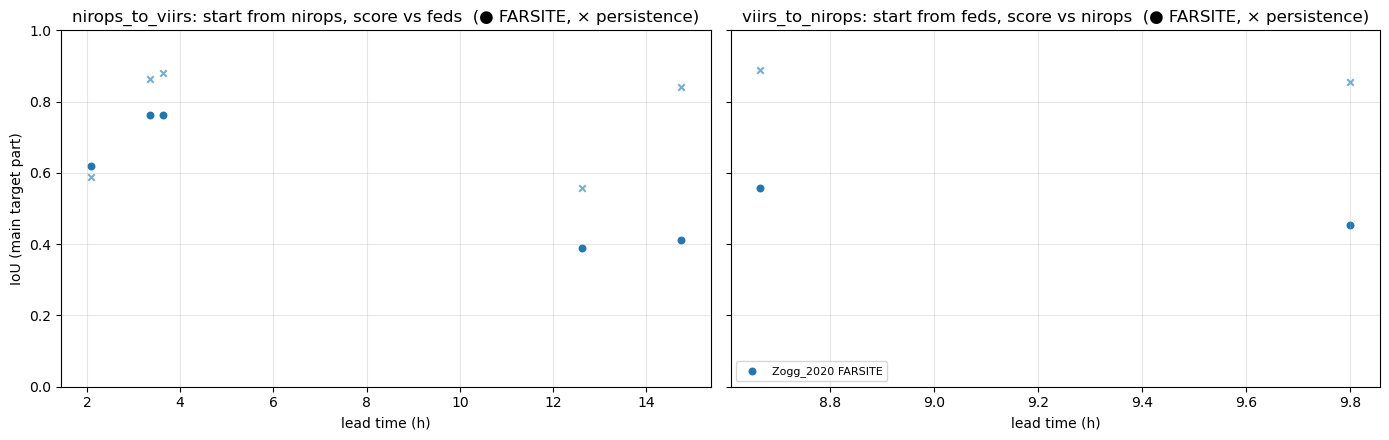

figure → fires/experiments_iou_vs_lead.png
fires with experiment results: ['Zogg_2020']


,experiment,fire,lead_bin,n,iou,iou_persist,iou_gain,iou_full,area_err_pct
0,nirops_to_viirs,Zogg_2020,0–12 h,3,0.715,0.777,-0.062,0.715,27.322
1,nirops_to_viirs,Zogg_2020,12–24 h,2,0.401,0.700,-0.299,0.401,145.202
2,viirs_to_nirops,Zogg_2020,0–12 h,2,0.506,0.872,-0.366,0.506,99.209


In [17]:
m = load_experiment_metrics()          # every fire with saved experiment results, from any copy
plot_experiments(m)
if len(m):
    print('fires with experiment results:', sorted(m.fire.unique()))
    m['lead_bin'] = pd.cut(m.lead_h, [0, 12, 24, 48, np.inf], labels=['0–12 h', '12–24 h', '24–48 h', '>48 h'])
    exp_summary = (m.groupby(['experiment', 'fire', 'lead_bin'], observed=True)
                     .agg(n=('iou', 'size'), iou=('iou', 'mean'), iou_persist=('iou_persist', 'mean'),
                          iou_gain=('iou_gain', 'mean'), iou_full=('iou_full', 'mean'),
                          area_err_pct=('area_err_pct', 'median'))
                     .round(3).reset_index())
    exp_summary.to_csv(OUTPUT_ROOT / 'experiments_summary.csv', index=False)
    display(exp_summary)
else:
    print('No saved experiment results yet (EXP_DRY_RUN = True, or no forecasts inside the window).')

## 12. Worked example: Zogg Fire (2020)

A complete run for one fire. It's the quickest way to see the whole workflow, and a template for the other fires.
Zogg is a good first case: a single ignition, clean NIROPS and FEDS records, and most of its growth in the first 36 h.

**To run it:** run Sections 1–7, then the Section 11 definitions cell (`EXPERIMENTS = …`), then this section.
Sections 8–11's *run* cells can be skipped. With Run All they only plan (`DRY_RUN = True`), which takes seconds.

| step | what it does | 3 days, 12 cores, spotting off |
|---|---|---|
| 12.2 | full forward run from the ignition point, scored at every NIROPS/FEDS time | ~120 steps, ~15 min |
| 12.3 | wind and humidity the run used (are they representative?) | seconds |
| 12.4 | restart experiments (i) NIROPS → VIIRS and (ii) VIIRS → NIROPS, with the persistence baseline | ~100 steps, ~12 min |
| 12.5 | map panels and summary figures for the experiments | seconds |

The first run after an update may also rebuild the landscape (a one-time LANDFIRE download of a few minutes).
These cells change session-wide settings (`FARSITE_NCORES`, spotting, Zogg's `max_sim_days`). Re-run Section 2 to reset
them. Inside `run_parallel.py` copies this section does nothing.

In [18]:
# 12.1 settings
ZOGG_KEY              = 'Zogg_2020'
ZOGG_DAYS             = 3        # simulated days after ignition; None = whole fire (last NIROPS 8 Oct; several hours)
ZOGG_NCORES           = 12       # one fire → give FARSITE every core
ZOGG_SPOT_PROBABILITY = 0.0      # 0.5 = original farsite.py setting (slower; raise FARSITE_TIMEOUT_MIN to 45–60)
ZOGG_RUN_MAIN         = False
ZOGG_RUN_EXPERIMENTS  = True

ZOGG_SKIP = bool(os.environ.get('FARSITE_FIRES') or os.environ.get('FARSITE_SUMMARY_ONLY'))
if ZOGG_SKIP:
    print('Headless run (run_parallel.py): worked example skipped.')
else:
    if ZOGG_DAYS is None:
        FIRES[ZOGG_KEY].pop('max_sim_days', None)
    else:
        FIRES[ZOGG_KEY]['max_sim_days'] = ZOGG_DAYS
    FARSITE_NCORES = ZOGG_NCORES
    SPOT_PROBABILITY = ZOGG_SPOT_PROBABILITY
    farsite.FARSITE_SPOT_PROBABILITY = ZOGG_SPOT_PROBABILITY
    print(f'{ZOGG_KEY}: {ZOGG_DAYS or "all"} day(s) | {FARSITE_NCORES} cores | spot probability {SPOT_PROBABILITY}')
    _ = plan_fire(ZOGG_KEY)                       # prints the plan (perimeters, segments, FARSITE steps)
    for _name in EXPERIMENTS:
        plan_experiment(ZOGG_KEY, _name)

Zogg_2020: 3 day(s) | 12 cores | spot probability 0.0

=== Zogg_2020 ===
  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]
  feds: re-timed to VIIRS overpass (11 of 34 from detections, rest by the median offset; median +10.2 h after the 12-h bin label)
  nirops           12 perimeters after ignition  2020-09-28 02:05:00 → 2020-10-08 20:50:00  (final 228.0 km², ≤7 part(s))
  feds             34 perimeters after ignition  2020-09-28 04:10:00 → 2020-10-14 15:15:00  (final 251.1 km², ≤1 part(s))
  start (ignition): 2020-09-27 14:50:00  0.031 km²
  scored vs nirops      :   3 perimeters, last 2020-09-29 23:55:00  219.75 km² main / 219.75 km² all parts
  scored vs feds        :   5 perimeters, last 2020-09-30 03:33:00  243.99 km² main / 243.99 km² al

### 12.2 Full forward run

Starts from a 100 m circle at the overlay's ignition point and time, never resets to observations, and is scored at every
NIROPS and (re-timed) FEDS perimeter. Outputs go to `fires/Zogg_2020/` (`*_metrics.csv`, `*_sim_steps.gpkg`,
`*_evaluation.png`).

In [19]:
zogg_main = None
if not ZOGG_SKIP and ZOGG_RUN_MAIN:
    zogg_main = run_fire(ZOGG_KEY)
    if zogg_main['metrics'] is not None and len(zogg_main['metrics']):
        display(zogg_main['metrics'][['series', 'time', 'area_sim_km2', 'area_obs_km2', 'iou', 'iou_full',
                                       'area_err_pct']].round(3))

### 12.3 Weather check

The run uses hourly observations from the single station nearest the ignition. Wind direction is where the wind blows
**from** (0° = north). If FARSITE spreads in a different direction than the real fire, check here first. For Zogg the
station shows NNW winds (320–355°) at 8–17 mph and 10–15 % RH. That's consistent with the forecast at the time, so the
inputs are plausible, but hourly means miss the gusts that drove the first night's run. The bottom panel shows the dead
fuel moistures FARSITE receives (Section 5).

  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]


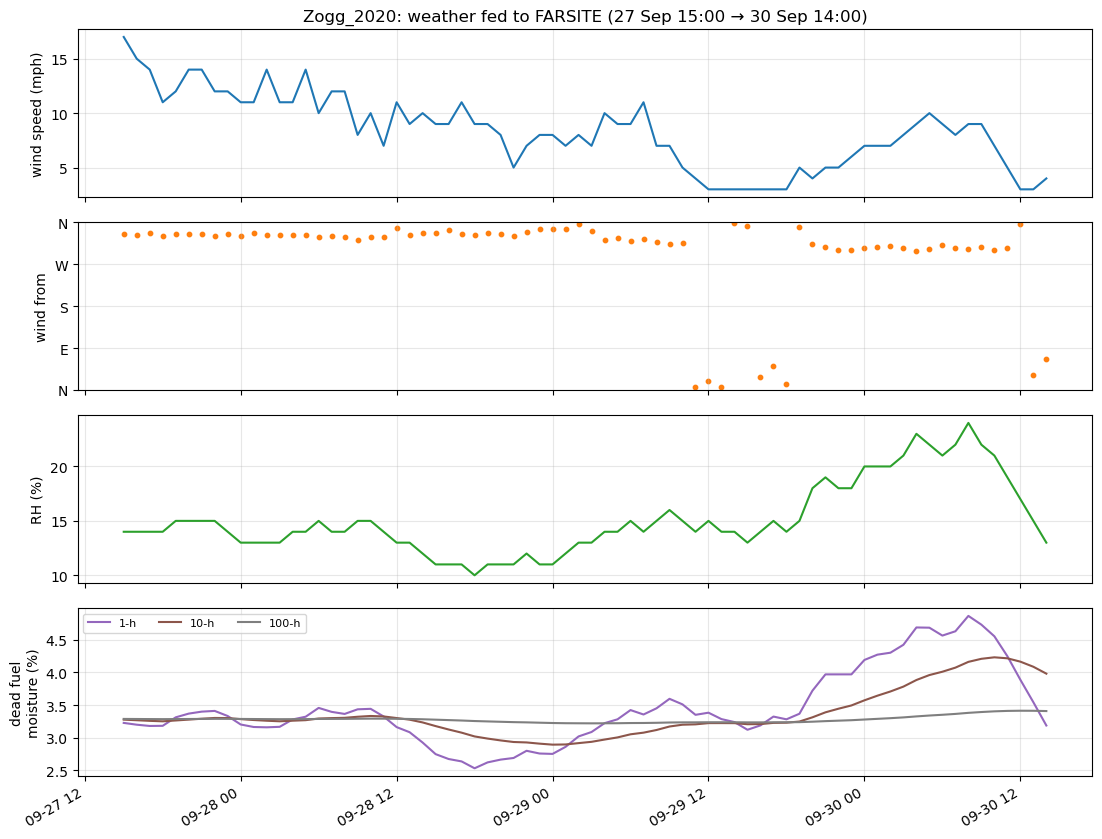

In [20]:
if not ZOGG_SKIP:
    _wx = pd.read_csv(OUTPUT_ROOT / ZOGG_KEY / 'weather.csv', index_col=0, parse_dates=True)
    _t0 = pd.Timestamp(resolve_fire(ZOGG_KEY)['start'])
    _w = _wx.loc[_t0: _t0 + pd.Timedelta(days=ZOGG_DAYS or 30)]
    fig, ax = plt.subplots(4, 1, sharex=True, figsize=(11, 8.5))
    ax[0].plot(_w.index, _w['windspeed'], color='#1f77b4'); ax[0].set_ylabel('wind speed (mph)')
    ax[1].scatter(_w.index, _w['winddirection'], s=10, color='#ff7f0e'); ax[1].set_ylim(0, 360)
    ax[1].set_yticks([0, 90, 180, 270, 360], ['N', 'E', 'S', 'W', 'N']); ax[1].set_ylabel('wind from')
    ax[2].plot(_w.index, _w['humidity'] * 100, color='#2ca02c'); ax[2].set_ylabel('RH (%)')
    _fm = dead_fuel_moisture(_wx).loc[_w.index.min(): _w.index.max()]
    if FUEL_MOISTURE_FROM_WEATHER and not _fm.empty:
        for _c, _col in (('fm1', '#9467bd'), ('fm10', '#8c564b'), ('fm100', '#7f7f7f')):
            ax[3].plot(_fm.index, _fm[_c], color=_col, label=_c.replace('fm', '') + '-h')
        ax[3].legend(fontsize=8, ncol=3); ax[3].set_ylabel('dead fuel\nmoisture (%)')
    else:
        ax[3].axhline(farsite.FUEL_MOISTURES_DATA[0][1], color='#9467bd', label='fixed 1-h')
        ax[3].legend(fontsize=8); ax[3].set_ylabel('fuel moisture (%)')
    for a in ax:
        a.grid(alpha=.3)
    ax[0].set_title(f'{ZOGG_KEY}: weather fed to FARSITE ({_w.index.min():%d %b %H:%M} → {_w.index.max():%d %b %H:%M})')
    fig.autofmt_xdate(); plt.tight_layout()
    plt.savefig(OUTPUT_ROOT / ZOGG_KEY / f'{ZOGG_KEY}_weather.png', dpi=150, bbox_inches='tight'); plt.show()

### 12.4 Restart experiments

- **(i) `nirops_to_viirs`:** each NIROPS perimeter restarts FARSITE, scored at the following VIIRS overpasses.
- **(ii) `viirs_to_nirops`:** each VIIRS (FEDS) perimeter restarts it, scored at the next NIROPS flight.

Each forecast is also compared with **persistence** (the input perimeter, unchanged). `iou_gain > 0` means FARSITE did
better than assuming the fire stopped.

In [21]:
zogg_exp = {}
if not ZOGG_SKIP and ZOGG_RUN_EXPERIMENTS:
    for _name in EXPERIMENTS:
        zogg_exp[_name] = run_experiment(ZOGG_KEY, _name)


=== Zogg_2020 · nirops_to_viirs ===
  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]
  [nirops_to_viirs] 3 nirops inputs, 5 feds targets in window → 3 forecasts scoring 5 targets (≈ 61 FARSITE steps)
  ✓ using cached fires/Zogg_2020/landscape.lcp
  ⚠ weather 24 Sep 12:50 → 27 Sep 12:50: no station data returned
  ⚠ weather 27 Sep 12:50 → 27 Sep 13:00: no station data returned
  weather: 390 obs (390 cached + 0 downloaded) from station(s) (cache); units: (cache)
  coverage: windspeed 100%, winddirection 100%, temperature 100%, humidity 100%
  ⚠ weather starts 2020-09-27 13:00:00, not 2020-09-24 14:50:00: fuel-moisture spin-up is 2 h instead of 72 h
  forecast 1/3: nirops @ 2020-09-28 02:05:00 (110.1 km²) → 2 feds target(s), last at +12.6 h
   

### 12.5 Experiment figures

Map panels (one per scored target): grey = perimeter FARSITE started from, blue = observed target, red = FARSITE.
The summary shows IoU against lead time (● FARSITE, × persistence, thin line = gain or loss) and the areas at each target.

  ignition from overlay: IRWIN reported origin (40.54120, -122.56831) at 2020-09-27 14:50:00
    closest to first perimeter (gofer_combined @ +0.2 h): IRWIN reported origin 0.4 km, GOFER metadata 0.1 km, MTBS event ID 0.3 km
    [registry: (40.5392, -122.566) at 2020-09-27 15:00, 0.30 km apart]


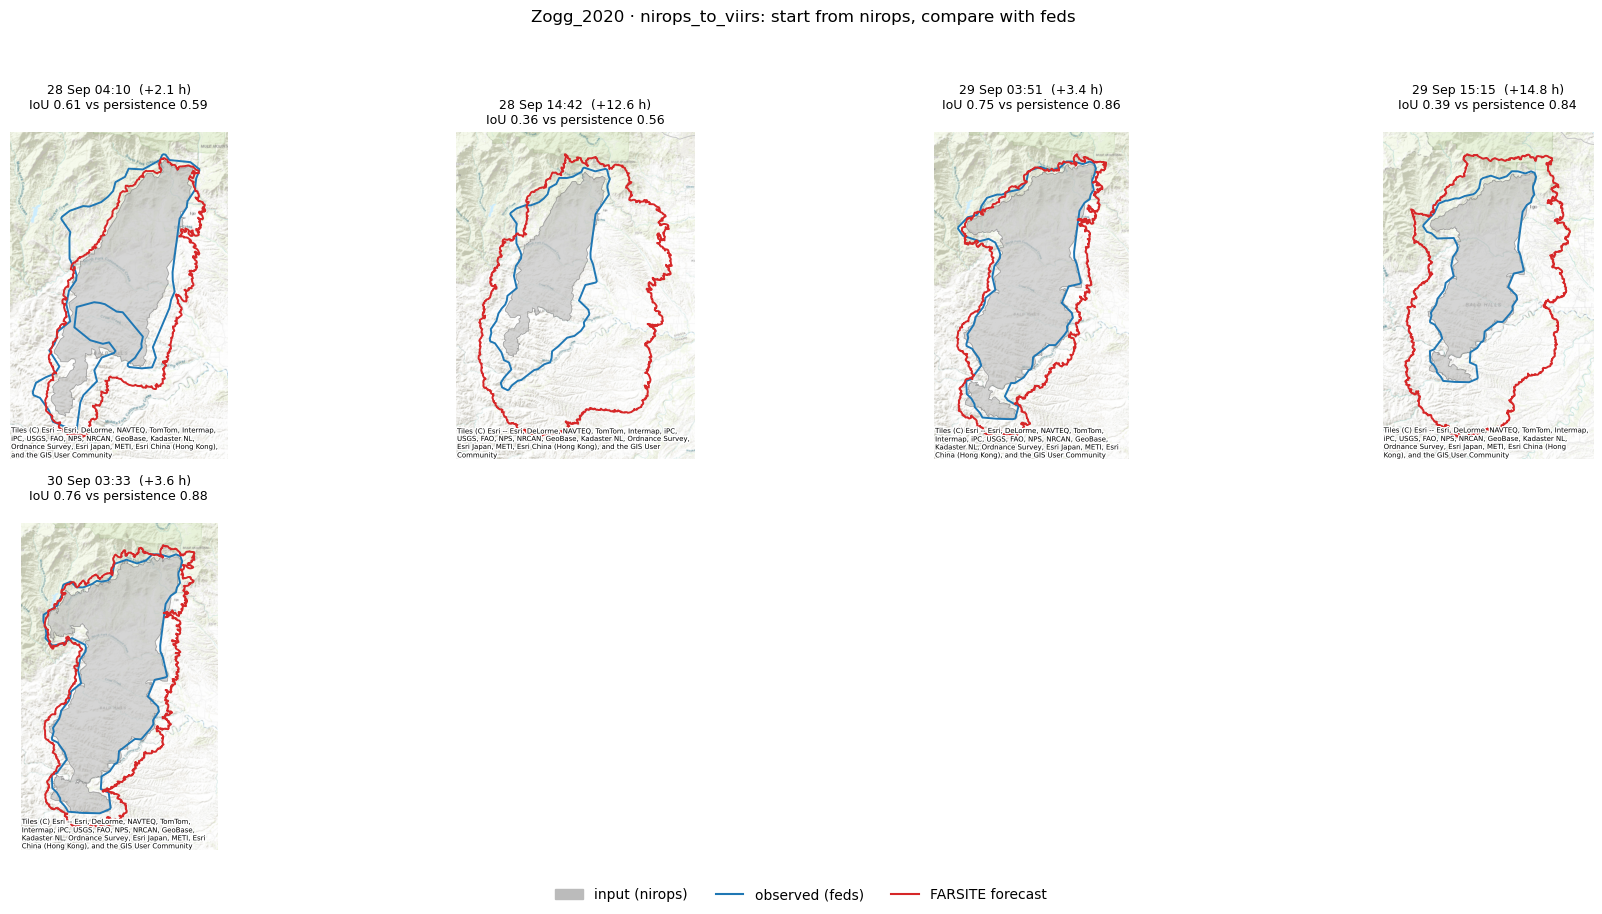

figure → fires/Zogg_2020/Zogg_2020_exp_nirops_to_viirs_maps.png


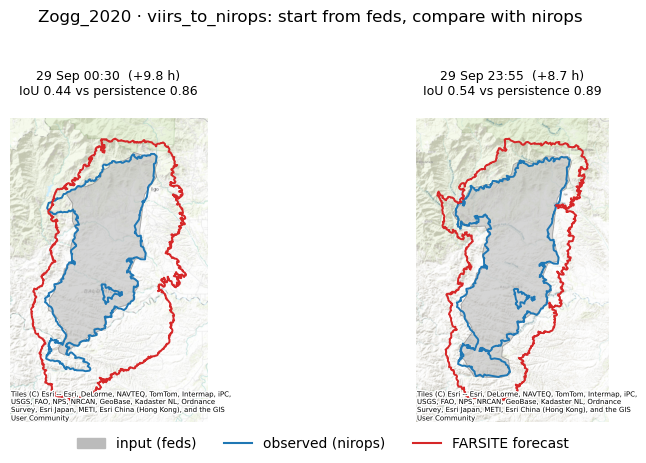

figure → fires/Zogg_2020/Zogg_2020_exp_viirs_to_nirops_maps.png


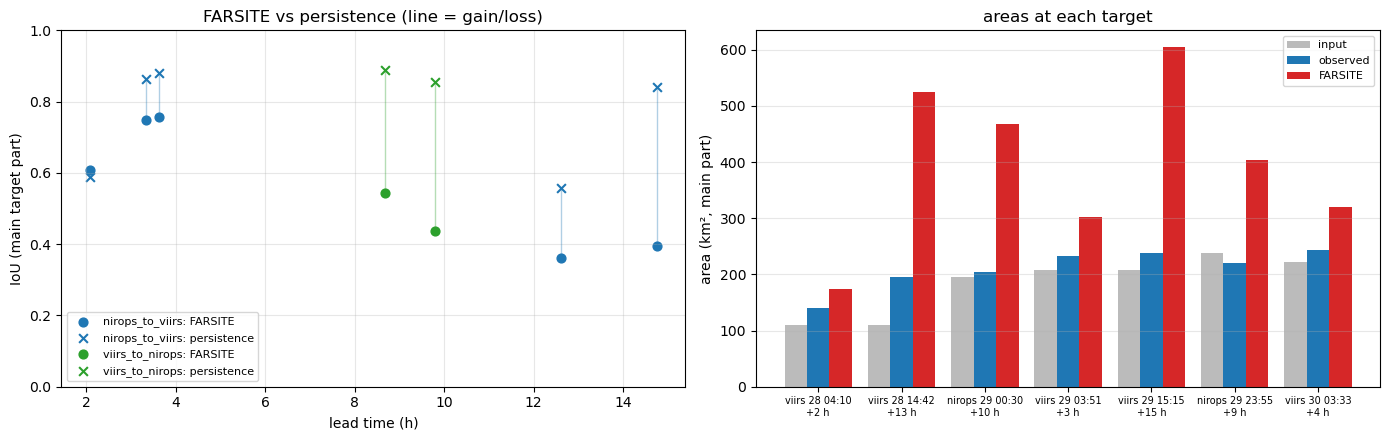

figure → fires/Zogg_2020/Zogg_2020_exp_summary.png


/tmp/ipykernel_10520/4135644570.py:84: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  return m[cols].round(3)


,experiment,input_time,target_time,lead_h,iou,iou_persist,iou_gain,area_sim_km2,area_obs_km2,input_area_km2
0,nirops_to_viirs,2020-09-28 02:05:00,2020-09-28 04:10:00,2.083,0.608,0.587,0.021,174.383,140.223,110.050
1,nirops_to_viirs,2020-09-28 02:05:00,2020-09-28 14:42:00,12.617,0.362,0.557,-0.195,524.399,195.897,110.050
2,viirs_to_nirops,2020-09-28 14:42:00,2020-09-29 00:30:00,9.800,0.436,0.856,-0.420,468.363,204.732,195.897
3,nirops_to_viirs,2020-09-29 00:30:00,2020-09-29 03:51:00,3.350,0.749,0.864,-0.114,301.585,232.077,207.222
4,nirops_to_viirs,2020-09-29 00:30:00,2020-09-29 15:15:00,14.750,0.394,0.842,-0.448,604.439,238.120,207.222
5,viirs_to_nirops,2020-09-29 15:15:00,2020-09-29 23:55:00,8.667,0.543,0.888,-0.345,404.418,219.747,238.120
6,nirops_to_viirs,2020-09-29 23:55:00,2020-09-30 03:33:00,3.633,0.757,0.881,-0.125,319.396,243.990,222.082


In [22]:
def plot_fire_experiments(fire_key, show_basemap=True):
    fire_dir = OUTPUT_ROOT / fire_key
    fire = resolve_fire(fire_key)

    def _naive(s):
        s = pd.to_datetime(s)
        return s.dt.tz_convert(None) if getattr(s.dt, 'tz', None) is not None else s

    def _basemap(ax):
        if not (show_basemap and BASEMAP):
            return
        try:
            import contextily as ctx
            ctx.add_basemap(ax, source=ctx.providers.query_name(BASEMAP), crs='EPSG:3857', attribution_size=5)
        except Exception as e:
            print(f'  basemap skipped: {e}')

    all_rows = []
    for name, (inp, tgt) in EXPERIMENTS.items():
        gp = fire_dir / f'{fire_key}_exp_{name}.gpkg'
        if not gp.exists():
            print(f'{name}: no saved results ({gp.name} missing: not run yet, EXP_DRY_RUN was True, '
                  f'or no forecasts fit the window)')
            continue
        sims = gpd.read_file(gp).to_crs(5070)
        sims['input_time'], sims['target_time'] = _naive(sims['input_time']), _naive(sims['target_time'])
        P = fetch_overlay_perimeters(fire, [inp, tgt], verbose=False)
        pick = lambda series, t, col: P[(P.series == series) & (P.datetime == t)][col].iloc[0]
        sims['input_geom'] = [_input_polygon(pick(inp, t, 'geometry')) for t in sims.input_time]
        sims['obs_geom'] = [pick(tgt, t, 'geometry_full') for t in sims.target_time]
        all_rows.append(sims.assign(experiment=name))

        n = len(sims); ncols = min(n, 4); nrows = int(np.ceil(n / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.6 * nrows), squeeze=False)
        for ax, (_, r) in zip(axes.flat, sims.iterrows()):
            layers = gpd.GeoDataFrame({'what': ['input', 'observed', 'FARSITE']},
                                      geometry=[r.input_geom, r.obs_geom, r.geometry], crs=5070).to_crs(3857)
            layers.iloc[[0]].plot(ax=ax, color='#bbbbbb', alpha=0.6, edgecolor='#777777', lw=0.6)
            layers.iloc[[1]].boundary.plot(ax=ax, color='#1f77b4', lw=1.4)
            layers.iloc[[2]].boundary.plot(ax=ax, color='#d62728', lw=1.4)
            x0, y0, x1, y1 = layers.total_bounds; pad = 0.08 * max(x1 - x0, y1 - y0)
            ax.set_xlim(x0 - pad, x1 + pad); ax.set_ylim(y0 - pad, y1 + pad)
            _basemap(ax); ax.set_axis_off()
            ax.set_title(f'{r.target_time:%d %b %H:%M}  (+{r.lead_h:.1f} h)\n'
                         f'IoU {r.iou:.2f} vs persistence {r.iou_persist:.2f}', fontsize=9)
        for ax in axes.flat[n:]:
            ax.set_visible(False)
        fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color='#bbbbbb', label=f'input ({inp})'),
                            Line2D([], [], color='#1f77b4', label=f'observed ({tgt})'),
                            Line2D([], [], color='#d62728', label='FARSITE forecast')],
                   loc='lower center', ncol=3, frameon=False)
        fig.suptitle(f'{fire_key} · {name}: start from {inp}, compare with {tgt}', fontsize=12)
        plt.tight_layout(rect=(0, 0.05, 1, 0.95))
        out = fire_dir / f'{fire_key}_exp_{name}_maps.png'
        plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show(); print(f'figure → {out}')

    if not all_rows:
        return None
    m = pd.concat(all_rows, ignore_index=True)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
    colors = dict(zip(EXPERIMENTS, ['#1f77b4', '#2ca02c']))
    for name, g in m.groupby('experiment', sort=False):
        c = colors[name]
        a1.scatter(g.lead_h, g.iou, color=c, s=40, label=f'{name}: FARSITE')
        a1.scatter(g.lead_h, g.iou_persist, color=c, marker='x', s=40, label=f'{name}: persistence')
        for _, r in g.iterrows():
            a1.plot([r.lead_h, r.lead_h], [r.iou_persist, r.iou], color=c, alpha=0.35, lw=1)
    a1.set_xlabel('lead time (h)'); a1.set_ylabel('IoU (main target part)'); a1.set_ylim(0, 1)
    a1.grid(alpha=.3); a1.legend(fontsize=8); a1.set_title('FARSITE vs persistence (line = gain/loss)')
    m = m.sort_values('target_time').reset_index(drop=True)
    x = np.arange(len(m)); w = 0.27
    a2.bar(x - w, m.input_area_km2, w, color='#bbbbbb', label='input')
    a2.bar(x, m.area_obs_km2, w, color='#1f77b4', label='observed')
    a2.bar(x + w, m.area_sim_km2, w, color='#d62728', label='FARSITE')
    a2.set_xticks(x, [f'{r.experiment.split("_to_")[1]} {r.target_time:%d %H:%M}\n+{r.lead_h:.0f} h'
                      for r in m.itertuples()], fontsize=7)
    a2.set_ylabel('area (km², main part)'); a2.grid(alpha=.3, axis='y'); a2.legend(fontsize=8)
    a2.set_title('areas at each target')
    plt.tight_layout()
    out = fire_dir / f'{fire_key}_exp_summary.png'
    plt.savefig(out, dpi=150, bbox_inches='tight'); plt.show(); print(f'figure → {out}')
    cols = ['experiment', 'input_time', 'target_time', 'lead_h', 'iou', 'iou_persist', 'iou_gain',
            'area_sim_km2', 'area_obs_km2', 'input_area_km2']
    return m[cols].round(3)

if not ZOGG_SKIP:
    zogg_exp_table = plot_fire_experiments(ZOGG_KEY)
    if zogg_exp_table is not None:
        display(zogg_exp_table)

### 12.6 Reading the results

- **IoU** (intersection over union) runs from 0 to 1. Roughly: above 0.5 is a decent match, below 0.3 is poor.
  `iou` scores the observed part nearest the ignition (or overlapping the input); `iou_full` scores all mapped parts.
- **Area error** shows whether FARSITE grows the fire too slowly (negative) or too fast (positive).
- **Free run (12.2):** errors accumulate, because nothing pulls the simulation back to the observations. In the 3-day test
  run (spotting off), FARSITE grew too slowly through the first night (−56 % at the 02:05 NIROPS flight), then about 2×
  too large by day 2. It also spread more to the south-east than the real fire, giving IoU of 0.13–0.23.
- **Restart experiments (12.4):** the fairer test. In the same test, FARSITE beat persistence only at the shortest lead
  (+2 h: 0.62 vs 0.59). At every 9–15 h lead it roughly doubled the observed area. Its main error is over-growth after the
  initial run, which is typical for FARSITE without suppression, with fixed fuel moistures and no overnight recovery.
- **Fuel moisture:** dead fuel moisture now follows the weather (Section 5). The test numbers above came from the old
  fixed values `[1-h 7, 10-h 4, 100-h 7]`, so re-run 12.2–12.5 to see the effect. Set `FUEL_MOISTURE_FROM_WEATHER = False`
  to compare.
- **Things to try:** spotting on (`ZOGG_SPOT_PROBABILITY = 0.5`), the whole fire (`ZOGG_DAYS = None`), live fuel moisture
  (`FIRES['Zogg_2020']['live_fm'] = (herb, woody)`), or another weather source.